# Lab 4: Dự Báo Chuỗi Thời Gian Đa Biến (Multivariate Time Series Forecasting)
**Bài toán:** Dự báo phụ tải điện năng hàng giờ kết hợp dữ liệu thời tiết (`Electricity Load + Weather`)  
**Mô hình đối chứng:** `VAR` (Statistical Baseline) · `XGBoost` (Machine Learning) · `LSTM` (Deep Learning)  
**Tham chiếu:** [`practice 4.pdf`](../../practice%204.pdf)

---

## Mục 1 & 2: Mục Tiêu, Dữ Liệu & Định Nghĩa Bài Toán
* **Vector quan sát đa biến tại thời điểm $t$:** $X_t = [\text{load}_t,\ \text{temperature}_t,\ \text{humidity}_t,\ \text{wind\_speed}_t]$
* **Công thức dự báo:** Dùng cửa sổ lịch sử $L = 24$ giờ gần nhất dự báo phụ tải bước kế tiếp:
  $$X_{t-23:t} \Rightarrow \text{load}_{t+1}$$
* **Bộ dữ liệu thực nghiệm:** [Kaggle — Hourly Energy Demand Generation and Weather (Spain)](https://www.kaggle.com/datasets/nicholasjhana/energy-consumption-generation-prices-and-weather) (`35,064` giờ liên tục từ `2015` đến `2018`).

In [1]:
import json
import sys
from pathlib import Path
import joblib
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

plt.rcParams["figure.dpi"] = 150
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from scripts.config import Config
from scripts.data_loader import MultivariateDataLoader
from scripts.feature_engineering import MultivariateFeatureBuilder
from scripts.evaluation import evaluate_multivariate_forecast, residual_diagnostics
from scripts.models import (
    VARForecaster,
    XGBoostMultivariateForecaster,
    LSTMForecaster,
    tune_xgboost_multivariate,
)

print("Project Root :", Config.BASE_DIR)
print("Features     :", Config.FEATURES)
print("Lookback (L) :", Config.LOOKBACK, "hours")
print("Split Ratios :", Config.SPLIT_RATIOS)

Project Root : E:\TimeSeries\Lab4_TS
Features     : ['load', 'temperature', 'humidity', 'wind_speed']
Lookback (L) : 24 hours
Split Ratios : {'train': 0.7, 'val': 0.15, 'test': 0.15}


---
## Mục 3: Data Understanding (Kiểm Tra Chất Lượng Dữ Liệu & Trực Quan Hóa EDA)
* Kiểm tra **Missing values** (`load` thiếu `36` giờ), **Outliers** (`wind_speed > 40 m/s` xuất hiện bất thường tới `133 m/s` trong bản ghi thô), **Seasonality** (chu kỳ ngày & tuần).
* Trực quan hóa dữ liệu gốc kèm ngưỡng `Mean / Max / Min`, kiểm định missing/outliers, `load` vs `temperature` và **Correlation Matrix**.

In [2]:
loader = MultivariateDataLoader()
df_clean, audit = loader.load_clean_multivariate(export_path=None)

print(f"Merged Clean Shape : {df_clean.shape} ({audit['start_time']} -> {audit['end_time']})")
print(f"Cities Aggregated  : {', '.join(audit['cities'])}")
print(f"Raw Missing Values : {audit['raw_nan_counts']}")
print(f"Raw Wind Outliers  : {audit['raw_wind_outliers_gt40ms']} records > 40 m/s cleaned before interpolation")
print("\n=== Summary Statistics ===")
print(pd.DataFrame(audit["summary_stats"]).T.round(2).to_string())
print("\n=== Pearson Correlation Matrix ===")
print(df_clean.corr(method="pearson").round(4).to_string())

Merged Clean Shape : (35064, 4) (2014-12-31 23:00:00+00:00 -> 2018-12-31 22:00:00+00:00)
Cities Aggregated  : Barcelona, Bilbao, Madrid, Seville, Valencia
Raw Missing Values : {'load': 36, 'temperature': 0, 'humidity': 0, 'wind_speed': 0}
Raw Wind Outliers  : 4 records > 40 m/s cleaned before interpolation

=== Summary Statistics ===
                 mean      std       min       q25    median       q75       max
load         28698.28  4575.83  18041.00  24807.00  28902.00  32194.25  41015.00
temperature     16.53     7.26     -1.21     10.91     15.88     21.94     36.12
humidity        68.22    14.89     22.60     56.80     69.80     80.20    100.00
wind_speed       2.47     1.35      0.00      1.40      2.20      3.20     12.80

=== Pearson Correlation Matrix ===
               load  temperature  humidity  wind_speed
load         1.0000       0.2033   -0.3661      0.1965
temperature  0.2033       1.0000   -0.6746      0.1018
humidity    -0.3661      -0.6746    1.0000     -0.3446
win

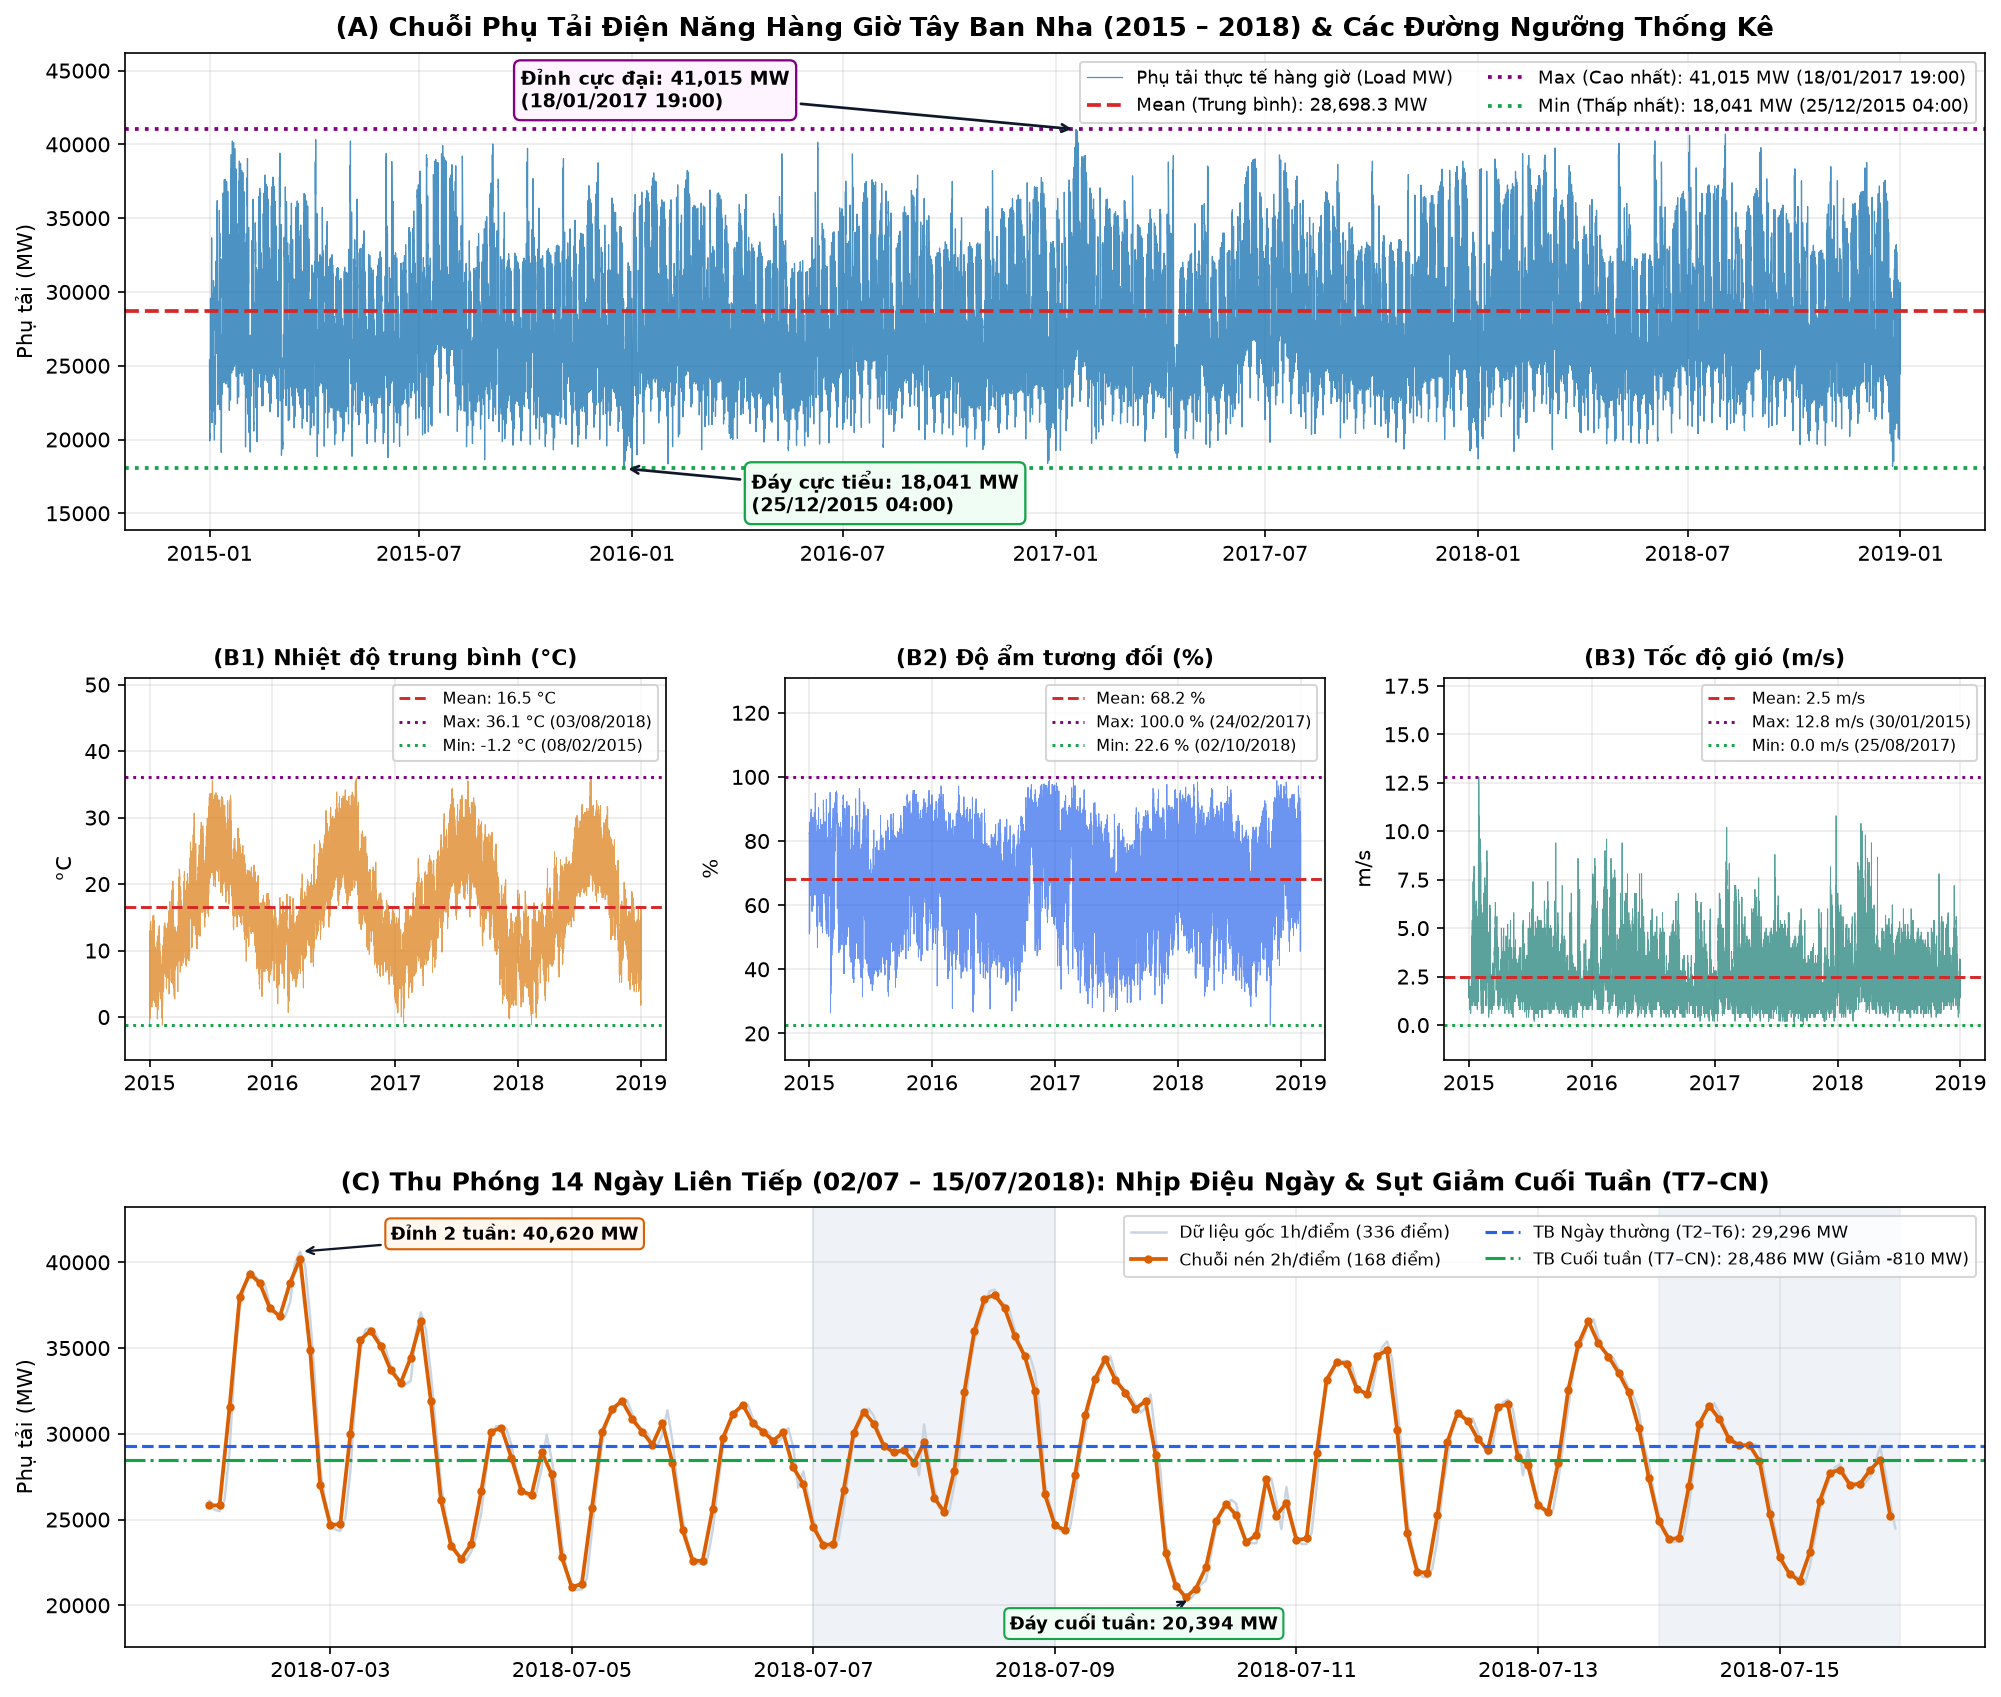

In [3]:
# Biểu đồ 01: Dữ liệu gốc 4 biến kèm các đường ngưỡng Mean/Max/Min & Thu phóng 14 ngày
fig = plt.figure(figsize=(16, 13.8))
gs = fig.add_gridspec(3, 1, height_ratios=[1.25, 1.0, 1.15], hspace=0.34)

ax_load = fig.add_subplot(gs[0])
s_load = df_clean["load"]
mean_l, max_l, min_l = float(s_load.mean()), float(s_load.max()), float(s_load.min())
max_ts_l, min_ts_l = s_load.idxmax(), s_load.idxmin()

ax_load.plot(s_load.index, s_load.values, color="#1f77b4", lw=0.6, alpha=0.80, label="Phụ tải thực tế hàng giờ (Load MW)")
ax_load.axhline(mean_l, color="#d62728", ls="--", lw=1.8, label=f"Mean (Trung bình): {mean_l:,.1f} MW")
ax_load.axhline(max_l, color="#800080", ls=":", lw=1.8, label=f"Max (Cao nhất): {max_l:,.0f} MW ({max_ts_l.strftime('%d/%m/%Y %H:%M')})")
ax_load.axhline(min_l, color="#16a34a", ls=":", lw=1.8, label=f"Min (Thấp nhất): {min_l:,.0f} MW ({min_ts_l.strftime('%d/%m/%Y %H:%M')})")
ax_load.annotate(
    f"Đỉnh cực đại: {max_l:,.0f} MW\n({max_ts_l.strftime('%d/%m/%Y %H:%M')})",
    xy=(max_ts_l, max_l), xytext=(max_ts_l - pd.Timedelta(days=480), max_l + 1500),
    fontsize=9, fontweight="bold", bbox=dict(boxstyle="round,pad=0.35", fc="#fdf4ff", ec="#800080", lw=1.1),
    arrowprops=dict(arrowstyle="->", color="#0f172a", lw=1.3),
)
ax_load.annotate(
    f"Đáy cực tiểu: {min_l:,.0f} MW\n({min_ts_l.strftime('%d/%m/%Y %H:%M')})",
    xy=(min_ts_l, min_l), xytext=(min_ts_l + pd.Timedelta(days=110), min_l - 2900),
    fontsize=9, fontweight="bold", bbox=dict(boxstyle="round,pad=0.35", fc="#f0fdf4", ec="#16a34a", lw=1.1),
    arrowprops=dict(arrowstyle="->", color="#0f172a", lw=1.3),
)
ax_load.set_ylim(min_l - 4200, max_l + 5200)
ax_load.set_title("(A) Chuỗi Phụ Tải Điện Năng Hàng Giờ Tây Ban Nha (2015 – 2018) & Các Đường Ngưỡng Thống Kê", fontsize=12.5, fontweight="bold", pad=8)
ax_load.set_ylabel("Phụ tải (MW)")
ax_load.legend(loc="upper right", fontsize=8.5, frameon=True, facecolor="white", ncol=2)

sub_gs = gs[1].subgridspec(1, 3, wspace=0.22)
for idx_w, (col, title, unit, base_col) in enumerate([
    ("temperature", "Nhiệt độ trung bình (°C)", "°C", "#d97706"),
    ("humidity", "Độ ẩm tương đối (%)", "%", "#2563eb"),
    ("wind_speed", "Tốc độ gió (m/s)", "m/s", "#0f766e"),
]):
    ax_w = fig.add_subplot(sub_gs[0, idx_w])
    sw = df_clean[col]
    w_mean, w_max, w_min = float(sw.mean()), float(sw.max()), float(sw.min())
    w_max_ts, w_min_ts = sw.idxmax(), sw.idxmin()
    span = w_max - w_min
    ax_w.plot(sw.index, sw.values, color=base_col, lw=0.45, alpha=0.68)
    ax_w.axhline(w_mean, color="#d62728", ls="--", lw=1.4, label=f"Mean: {w_mean:.1f} {unit}")
    ax_w.axhline(w_max, color="#800080", ls=":", lw=1.4, label=f"Max: {w_max:.1f} {unit} ({w_max_ts.strftime('%d/%m/%Y')})")
    ax_w.axhline(w_min, color="#16a34a", ls=":", lw=1.4, label=f"Min: {w_min:.1f} {unit} ({w_min_ts.strftime('%d/%m/%Y')})")
    ax_w.set_ylim(w_min - span * 0.14, w_max + span * 0.40)
    ax_w.set_title(f"(B{idx_w+1}) {title}", fontsize=10.5, fontweight="bold")
    ax_w.set_ylabel(unit)
    ax_w.xaxis.set_major_locator(mdates.YearLocator())
    ax_w.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax_w.legend(loc="upper right", fontsize=7.5, frameon=True, facecolor="white")

ax_z = fig.add_subplot(gs[2])
z_raw = df_clean.loc["2018-07-02":"2018-07-15", "load"]
z_2h = z_raw.resample("2h").mean()
wkday_mean = float(z_raw[z_raw.index.dayofweek < 5].mean())
wkend_mean = float(z_raw[z_raw.index.dayofweek >= 5].mean())
ax_z.plot(z_raw.index, z_raw.values, color="#cbd5e1", lw=1.2, label="Dữ liệu gốc 1h/điểm (336 điểm)")
ax_z.plot(z_2h.index, z_2h.values, color="#d95f02", lw=1.8, marker="o", ms=3.0, label="Chuỗi nén 2h/điểm (168 điểm)")
ax_z.axhline(wkday_mean, color="#2563eb", ls="--", lw=1.5, label=f"TB Ngày thường (T2–T6): {wkday_mean:,.0f} MW")
ax_z.axhline(wkend_mean, color="#16a34a", ls="-.", lw=1.5, label=f"TB Cuối tuần (T7–CN): {wkend_mean:,.0f} MW (Giảm {wkend_mean - wkday_mean:,.0f} MW)")
for wk_start, wk_end in [("2018-07-07 00:00:00+00:00", "2018-07-09 00:00:00+00:00"), ("2018-07-14 00:00:00+00:00", "2018-07-16 00:00:00+00:00")]:
    ax_z.axvspan(pd.Timestamp(wk_start), pd.Timestamp(wk_end), color="#e2e8f0", alpha=0.55)
z_max_ts, z_min_ts = z_raw.idxmax(), z_raw.idxmin()
ax_z.annotate(f"Đỉnh 2 tuần: {z_raw.max():,.0f} MW", xy=(z_max_ts, z_raw.max()), xytext=(z_max_ts + pd.Timedelta(hours=18), z_raw.max() + 700), fontsize=8.5, fontweight="bold", bbox=dict(boxstyle="round,pad=0.3", fc="#fff7ed", ec="#d95f02", lw=1.0), arrowprops=dict(arrowstyle="->", color="#0f172a", lw=1.1))
ax_z.annotate(f"Đáy cuối tuần: {z_raw.min():,.0f} MW", xy=(z_min_ts, z_raw.min()), xytext=(z_min_ts - pd.Timedelta(days=1.5), z_raw.min() - 1800), fontsize=8.5, fontweight="bold", bbox=dict(boxstyle="round,pad=0.3", fc="#f0fdf4", ec="#16a34a", lw=1.0), arrowprops=dict(arrowstyle="->", color="#0f172a", lw=1.1))
ax_z.set_ylim(z_raw.min() - 2800, z_raw.max() + 2600)
ax_z.set_title("(C) Thu Phóng 14 Ngày Liên Tiếp (02/07 – 15/07/2018): Nhịp Điệu Ngày & Sụt Giảm Cuối Tuần (T7–CN)", fontsize=12, fontweight="bold", pad=8)
ax_z.set_ylabel("Phụ tải (MW)")
ax_z.legend(loc="upper right", fontsize=8.3, frameon=True, facecolor="white", ncol=2)

fig.savefig(Config.IMAGE_DIR / "01_eda_load_and_weather_timeseries.png", bbox_inches="tight")
plt.show()

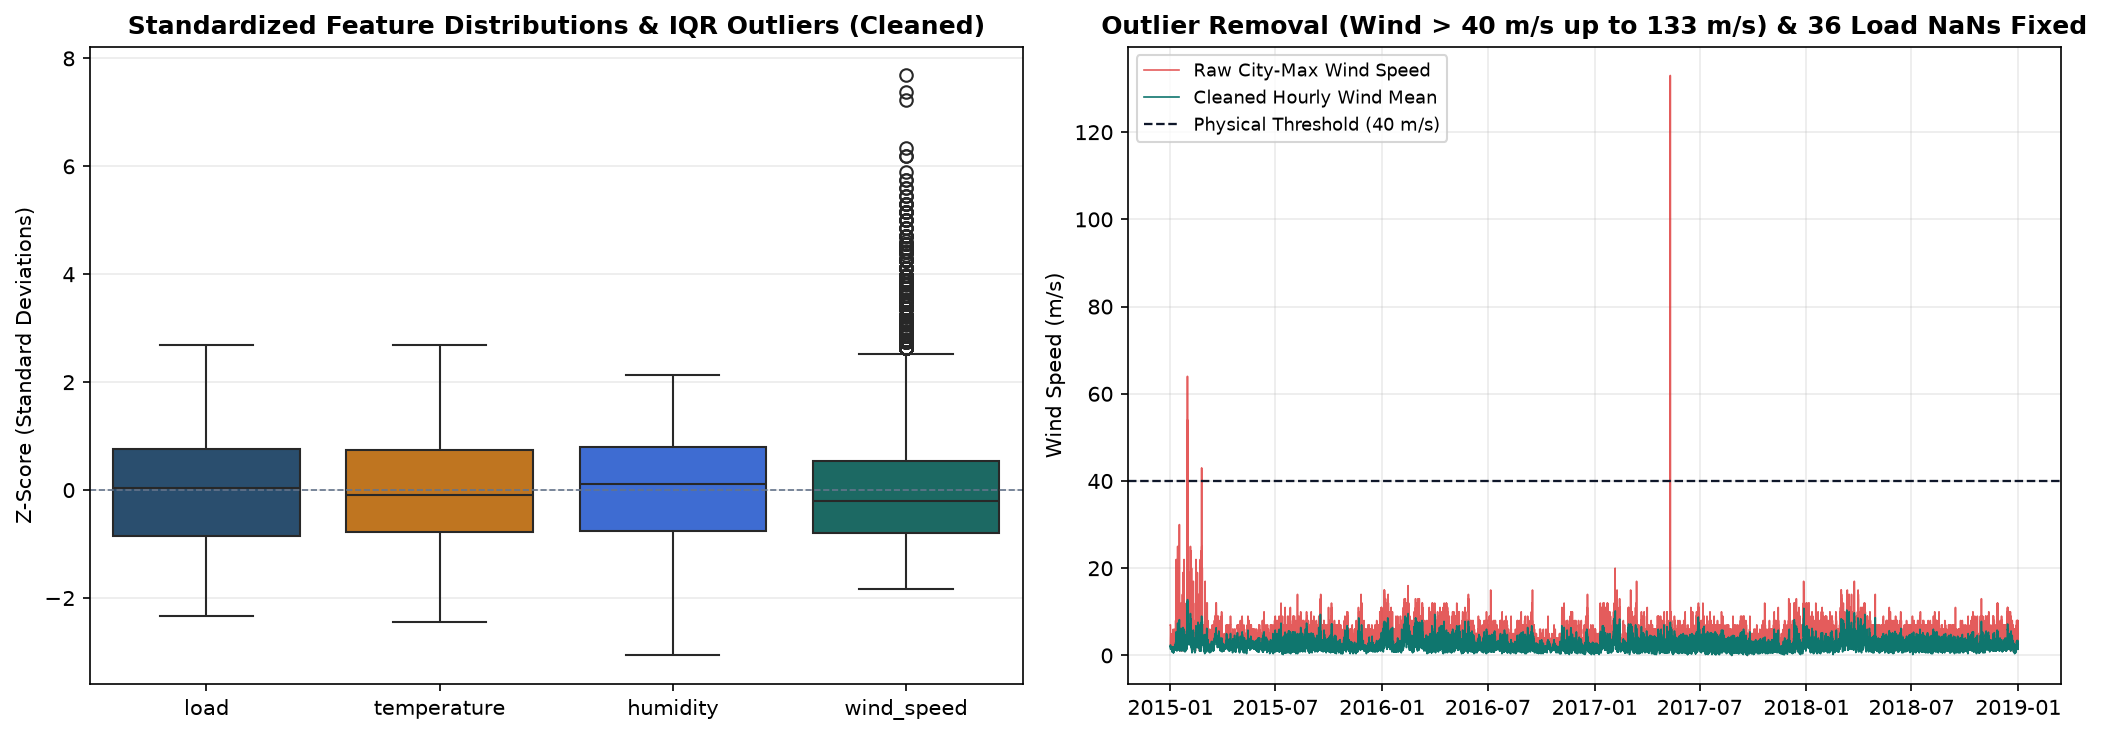

In [4]:
# Biểu đồ 11: Kiểm tra Boxplot Z-Score & làm sạch Outliers tốc độ gió > 40 m/s
df_e_raw = pd.read_csv(Config.RAW_ENERGY_PATH, usecols=["time", "total load actual"])
df_w_raw = pd.read_csv(Config.RAW_WEATHER_PATH, usecols=["dt_iso", "wind_speed"])
df_e_raw["dt"] = pd.to_datetime(df_e_raw["time"], utc=True)
df_w_raw["dt"] = pd.to_datetime(df_w_raw["dt_iso"], utc=True)
raw_wind_hourly = df_w_raw.groupby("dt")["wind_speed"].max()
nan_load_dt = df_e_raw.loc[df_e_raw["total load actual"].isna(), "dt"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.0))
z_df = (df_clean - df_clean.mean()) / df_clean.std()
sns.boxplot(data=z_df, ax=axes[0], palette=["#1f4e79", "#d97706", "#2563eb", "#0f766e"])
axes[0].axhline(0, color="#64748b", ls="--", lw=0.8)
axes[0].set_title("Standardized Feature Distributions & IQR Outliers (Cleaned)", fontweight="bold")
axes[0].set_ylabel("Z-Score (Standard Deviations)")

axes[1].plot(raw_wind_hourly.index, raw_wind_hourly.values, color="#dc2626", lw=0.8, alpha=0.75, label="Raw City-Max Wind Speed")
axes[1].plot(df_clean.index, df_clean["wind_speed"], color="#0f766e", lw=0.8, label="Cleaned Hourly Wind Mean")
axes[1].axhline(40, color="#0f172a", ls="--", lw=1.1, label="Physical Threshold (40 m/s)")
axes[1].set_title(f"Outlier Removal (Wind > 40 m/s up to {raw_wind_hourly.max():.0f} m/s) & {len(nan_load_dt)} Load NaNs Fixed", fontweight="bold")
axes[1].set_ylabel("Wind Speed (m/s)")
axes[1].legend(fontsize=8.5, loc="upper left")

fig.tight_layout()
fig.savefig(Config.IMAGE_DIR / "11_missing_values_and_outliers_audit.png", bbox_inches="tight")
plt.show()

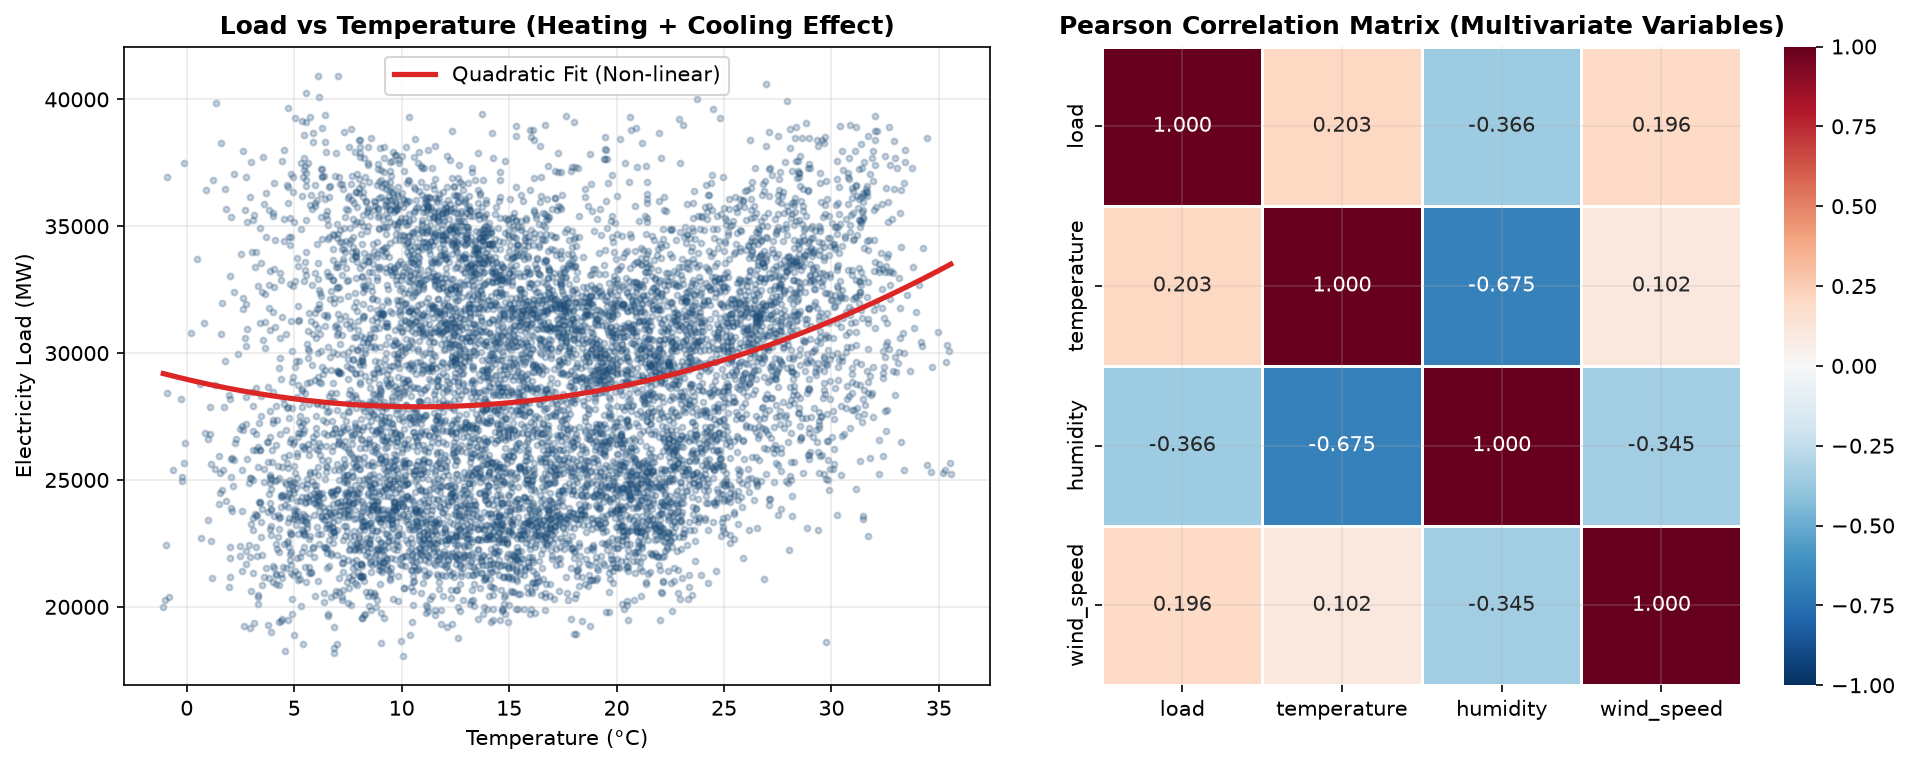

In [5]:
# Biểu đồ 02: Quan hệ phi tuyến Load vs Temperature & Ma trận tương quan Pearson
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
sample = df_clean.sample(min(8000, len(df_clean)), random_state=42)
axes[0].scatter(sample["temperature"], sample["load"], s=8, alpha=0.25, color="#1f4e79")
z_coef = np.polyfit(sample["temperature"], sample["load"], 2)
xs_t = np.linspace(sample["temperature"].min(), sample["temperature"].max(), 200)
axes[0].plot(xs_t, np.poly1d(z_coef)(xs_t), color="#dc2626", lw=2.5, label="Quadratic Fit (Non-linear)")
axes[0].set_title("Load vs Temperature (Heating + Cooling Effect)", fontweight="bold")
axes[0].set_xlabel("Temperature (°C)")
axes[0].set_ylabel("Electricity Load (MW)")
axes[0].legend()

sns.heatmap(df_clean.corr(method="pearson"), annot=True, fmt=".3f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True, linewidths=0.5, ax=axes[1])
axes[1].set_title("Pearson Correlation Matrix (Multivariate Variables)", fontweight="bold")

fig.tight_layout()
fig.savefig(Config.IMAGE_DIR / "02_eda_load_vs_temperature_and_corr.png", bbox_inches="tight")
plt.show()

---
## Mục 4 & 5: Preprocessing (`StandardScaler`), Chia Tập Theo Thời Gian & Feature Engineering
1. **Chia tập tuần tự (`shuffle=False`):** `70% Train` (`24,544` giờ) / `15% Validation` (`5,260` giờ) / `15% Test` (`5,260` giờ).
2. **Chuẩn hóa `StandardScaler`:** Chỉ `fit` trên tập Train, sau đó `transform` sang Validation và Test để chống **Data Leakage**. Khi đánh giá `RMSE / MAE / MAPE`, chuyển ngược giá trị dự báo về đơn vị gốc (`MW`).
3. **Feature Engineering ($L = 24$):**
   * Chung: $24 \times 4 = 96$ biến trễ đa biến (`load_lag_1..24`, `temperature_lag_1..24`, `humidity_lag_1..24`, `wind_speed_lag_1..24`).
   * Riêng **XGBoost** (+3 biến = **`99` features**): `rolling_mean_6`, `rolling_std_24`, `load_trend_24` ($load_t - load_{t-24}$).
   * Riêng **LSTM**: Tensor 3D kích thước `(batch_samples, 24, 4)`.

In [6]:
prepared = MultivariateFeatureBuilder.prepare_all(df_clean, export_dir=None, scaler_path=None)

for s_name, meta in prepared.split_summary.items():
    print(f"{s_name:<10} | Raw: {meta['raw_rows']:>6,} | Samples: {meta['sample_rows']:>6,} | {meta['start']} -> {meta['end']} | Mean={meta['load_mean_mw']:,.1f} MW")

print(f"\nXGBoost Feature Matrix : Train={prepared.X_xgb_train.shape}, Val={prepared.X_xgb_val.shape}, Test={prepared.X_xgb_test.shape}")
print(f"LSTM 3D Tensor Shape    : Train={prepared.X_lstm_train.shape}, Val={prepared.X_lstm_val.shape}, Test={prepared.X_lstm_test.shape}")
print(f"Train Scaled Check      : mean={prepared.df_train_scaled.mean().round(4).to_dict()}, std={prepared.df_train_scaled.std(ddof=0).round(4).to_dict()}")

Train      | Raw: 24,544 | Samples: 24,519 | 2014-12-31 23:00:00+00:00 -> 2017-10-19 14:00:00+00:00 | Mean=28,552.7 MW
Validation | Raw:  5,260 | Samples:  5,260 | 2017-10-19 15:00:00+00:00 -> 2018-05-26 18:00:00+00:00 | Mean=29,051.3 MW
Test       | Raw:  5,260 | Samples:  5,260 | 2018-05-26 19:00:00+00:00 -> 2018-12-31 22:00:00+00:00 | Mean=29,024.7 MW

XGBoost Feature Matrix : Train=(24519, 99), Val=(5260, 99), Test=(5260, 99)
LSTM 3D Tensor Shape    : Train=(24519, 24, 4), Val=(5260, 24, 4), Test=(5260, 24, 4)
Train Scaled Check      : mean={'load': 0.0, 'temperature': -0.0, 'humidity': 0.0, 'wind_speed': 0.0}, std={'load': 1.0, 'temperature': 1.0, 'humidity': 1.0, 'wind_speed': 1.0}


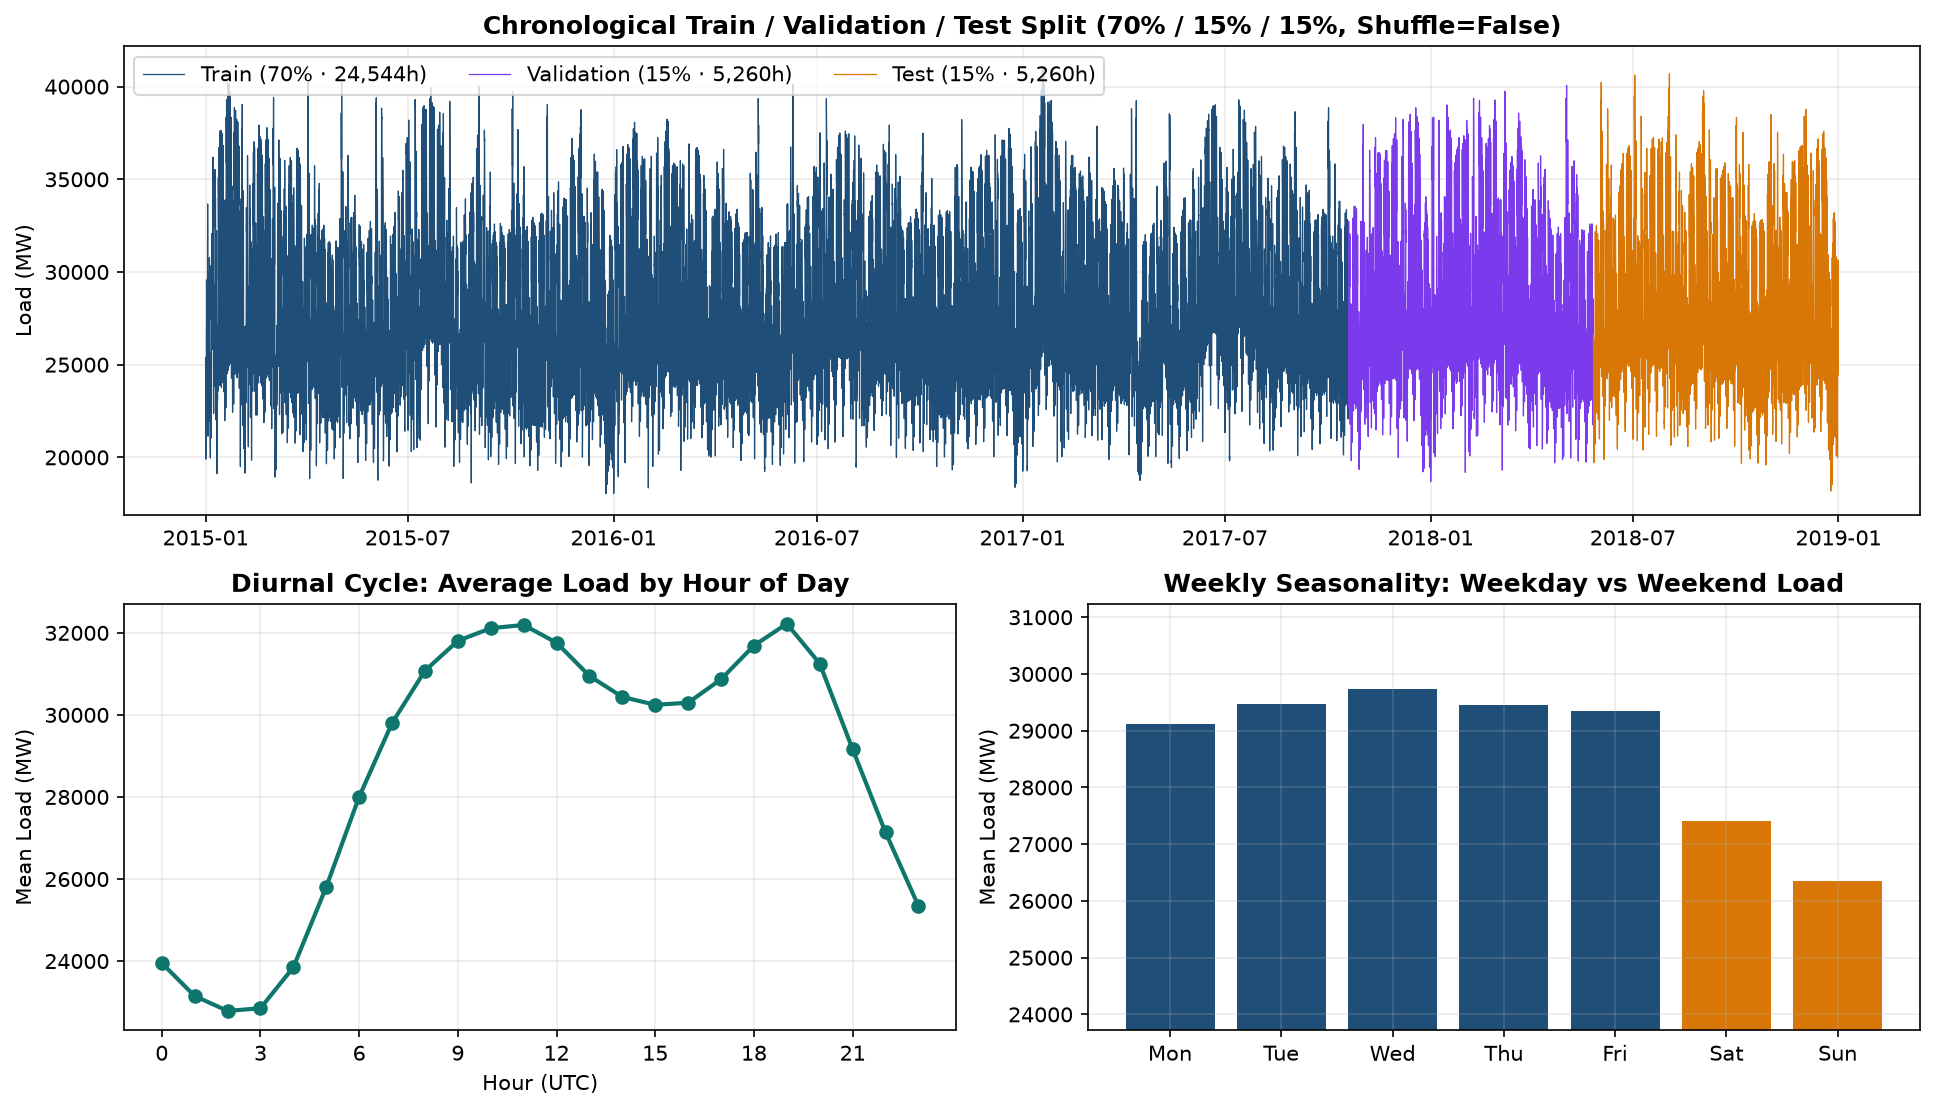

In [7]:
# Biểu đồ 03: Chia tập tuần tự 70/15/15 & Chu kỳ ngày / tuần
fig = plt.figure(figsize=(13, 7.5))
gs = fig.add_gridspec(2, 2, height_ratios=[1.1, 1.0])

ax_split = fig.add_subplot(gs[0, :])
ax_split.plot(prepared.df_train_raw.index, prepared.df_train_raw["load"], color="#1f4e79", lw=0.6, label=f"Train (70% · {len(prepared.df_train_raw):,}h)")
ax_split.plot(prepared.df_val_raw.index, prepared.df_val_raw["load"], color="#7c3aed", lw=0.6, label=f"Validation (15% · {len(prepared.df_val_raw):,}h)")
ax_split.plot(prepared.df_test_raw.index, prepared.df_test_raw["load"], color="#d97706", lw=0.6, label=f"Test (15% · {len(prepared.df_test_raw):,}h)")
ax_split.set_title("Chronological Train / Validation / Test Split (70% / 15% / 15%, Shuffle=False)", fontweight="bold")
ax_split.set_ylabel("Load (MW)")
ax_split.legend(loc="upper left", ncol=3)

ax_hr = fig.add_subplot(gs[1, 0])
hr_mean = df_clean.groupby(df_clean.index.hour)["load"].mean()
ax_hr.plot(hr_mean.index, hr_mean.values, marker="o", color="#0f766e", lw=2)
ax_hr.set_title("Diurnal Cycle: Average Load by Hour of Day", fontweight="bold")
ax_hr.set_xlabel("Hour (UTC)")
ax_hr.set_ylabel("Mean Load (MW)")
ax_hr.set_xticks(range(0, 24, 3))

ax_dow = fig.add_subplot(gs[1, 1])
dow_mean = df_clean.groupby(df_clean.index.dayofweek)["load"].mean()
ax_dow.bar(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], dow_mean.values, color=["#1f4e79"] * 5 + ["#d97706", "#d97706"])
ax_dow.set_title("Weekly Seasonality: Weekday vs Weekend Load", fontweight="bold")
ax_dow.set_ylabel("Mean Load (MW)")
ax_dow.set_ylim(dow_mean.min() * 0.9, dow_mean.max() * 1.05)

fig.tight_layout()
fig.savefig(Config.IMAGE_DIR / "03_seasonality_and_split.png", bbox_inches="tight")
plt.show()

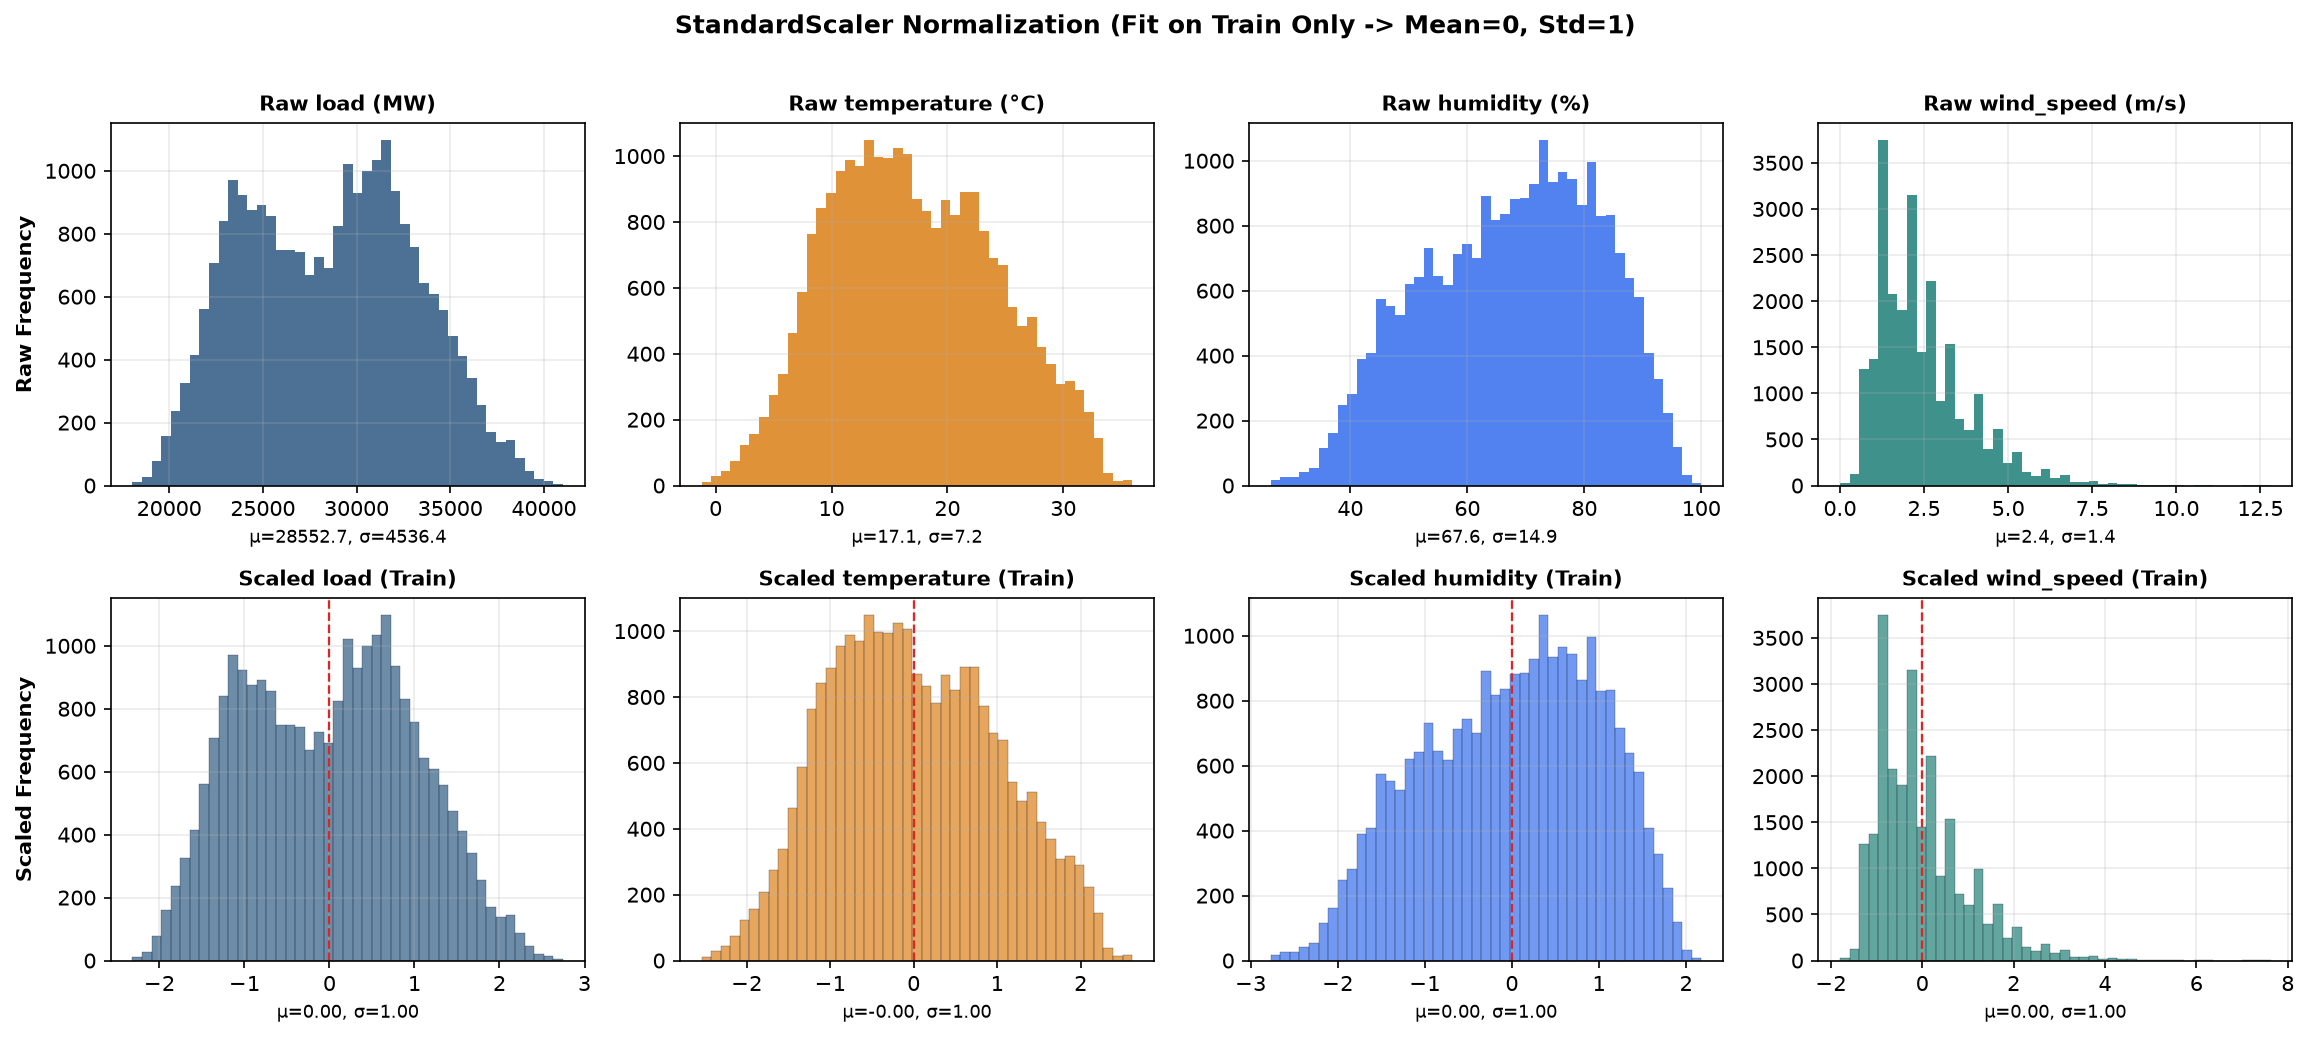

In [8]:
# Biểu đồ 12: Phân phối dữ liệu trước và sau chuẩn hóa StandardScaler trên tập Train
cols = list(prepared.df_train_raw.columns)
units = ["MW", "°C", "%", "m/s"]
colors = ["#1f4e79", "#d97706", "#2563eb", "#0f766e"]

fig, axes = plt.subplots(2, 4, figsize=(15.5, 6.8))
for j, (col, unit, color) in enumerate(zip(cols, units, colors)):
    axes[0, j].hist(prepared.df_train_raw[col], bins=45, color=color, alpha=0.8)
    axes[0, j].set_title(f"Raw {col} ({unit})", fontweight="bold", fontsize=10)
    axes[0, j].set_xlabel(f"μ={prepared.df_train_raw[col].mean():.1f}, σ={prepared.df_train_raw[col].std():.1f}", fontsize=8.5)
    axes[1, j].hist(prepared.df_train_scaled[col], bins=45, color=color, alpha=0.65, edgecolor="#0f172a", linewidth=0.2)
    axes[1, j].axvline(0, color="#dc2626", ls="--", lw=1.1)
    axes[1, j].set_title(f"Scaled {col} (Train)", fontweight="bold", fontsize=10)
    axes[1, j].set_xlabel(f"μ={prepared.df_train_scaled[col].mean():.2f}, σ={prepared.df_train_scaled[col].std(ddof=0):.2f}", fontsize=8.5)

axes[0, 0].set_ylabel("Raw Frequency", fontweight="bold")
axes[1, 0].set_ylabel("Scaled Frequency", fontweight="bold")
fig.suptitle("StandardScaler Normalization (Fit on Train Only -> Mean=0, Std=1)", fontweight="bold", fontsize=12, y=1.01)

fig.tight_layout()
fig.savefig(Config.IMAGE_DIR / "12_standard_scaler_distributions.png", bbox_inches="tight")
plt.show()

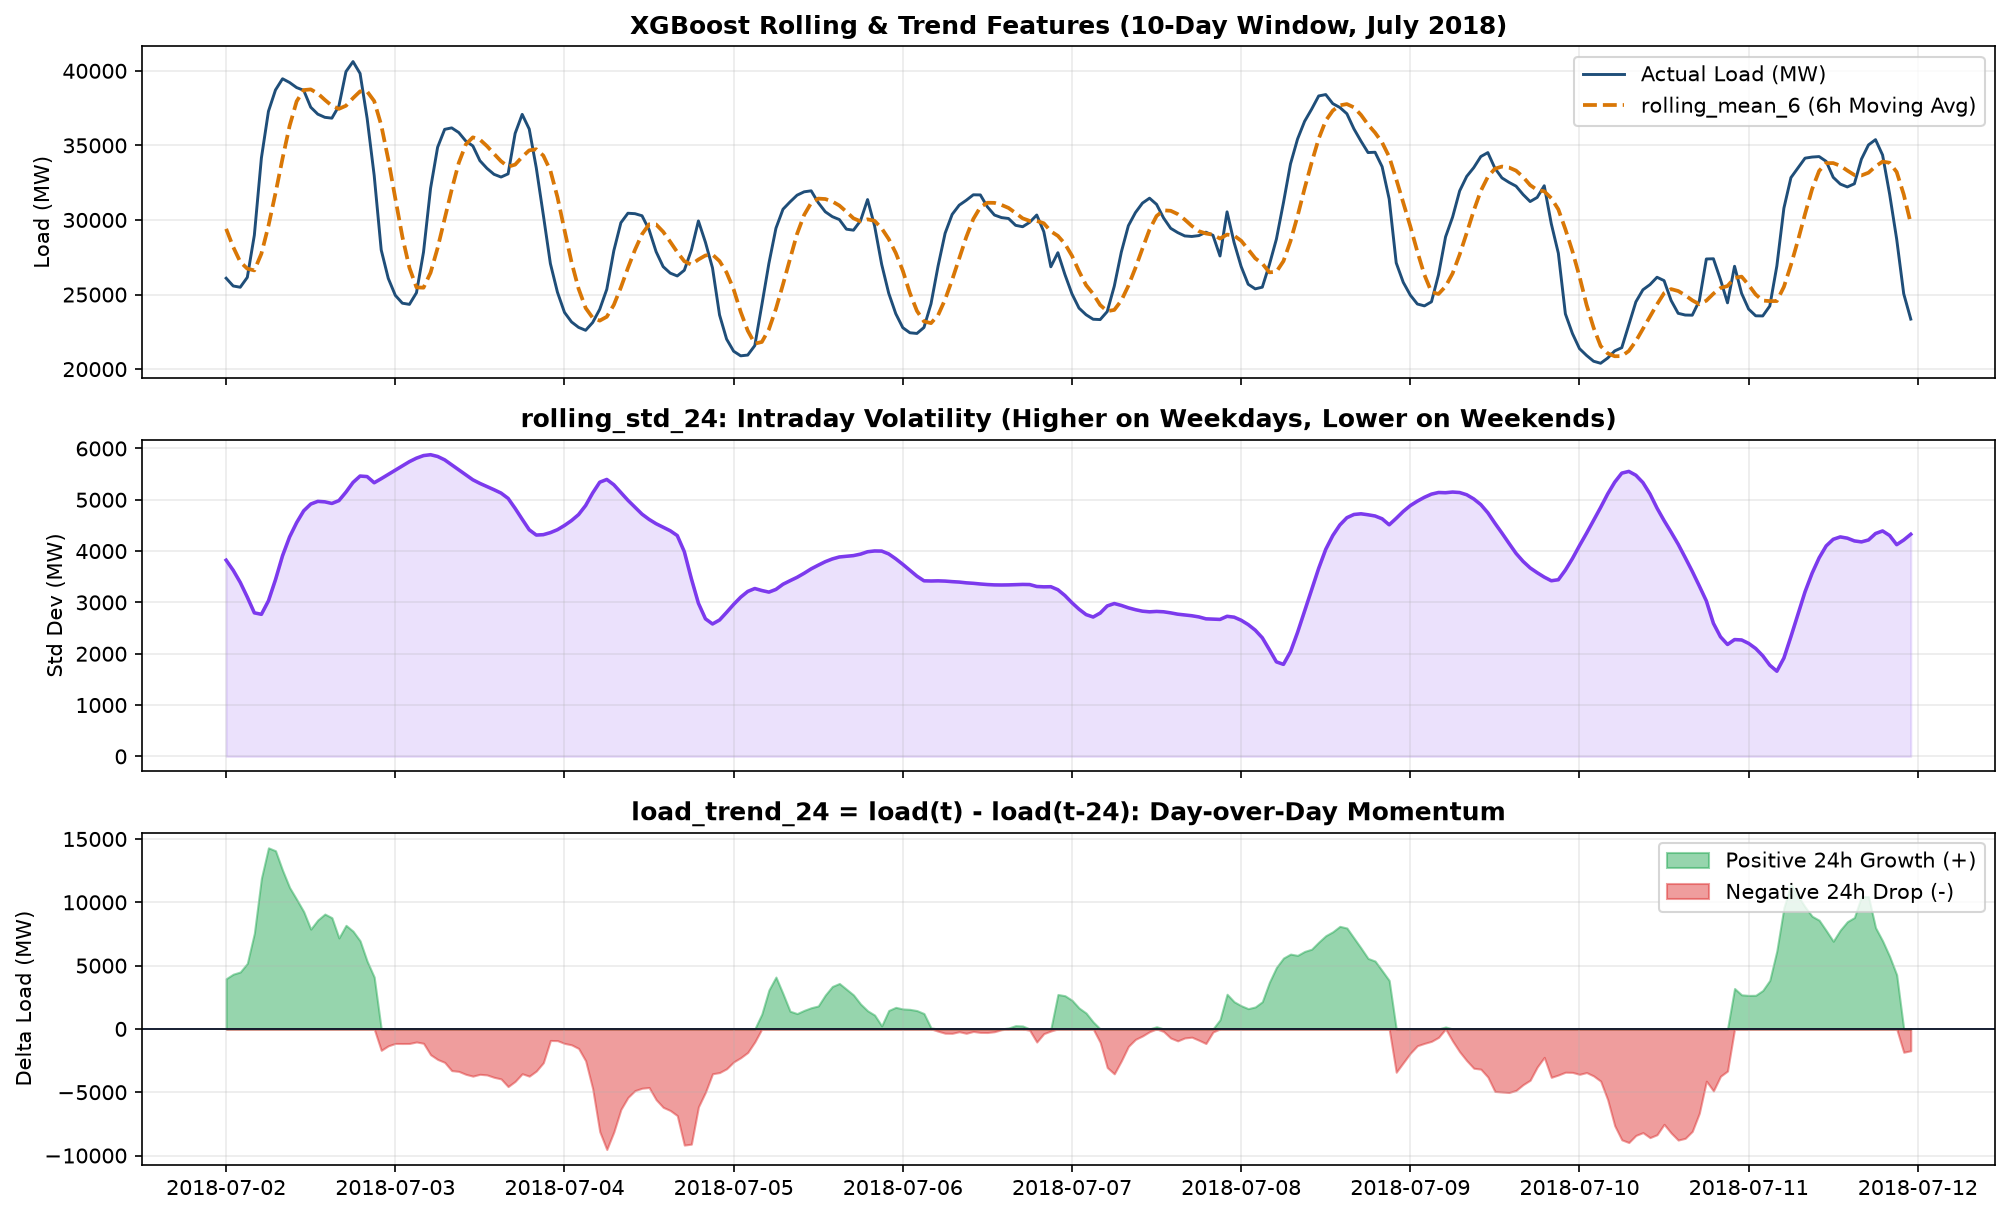

In [9]:
# Biểu đồ 13: Đặc trưng Rolling Mean 6h, Rolling Std 24h & Load Trend cho XGBoost
load_ser = df_clean["load"]
df_feat_vis = pd.DataFrame({
    "load": load_ser,
    "rolling_mean_6": load_ser.rolling(6).mean(),
    "rolling_std_24": load_ser.rolling(24).std(),
    "load_trend_24": load_ser - load_ser.shift(24),
}).dropna().loc["2018-07-02":"2018-07-11"]

fig, axes = plt.subplots(3, 1, figsize=(13.5, 8.2), sharex=True)
axes[0].plot(df_feat_vis.index, df_feat_vis["load"], color="#1f4e79", lw=1.4, label="Actual Load (MW)")
axes[0].plot(df_feat_vis.index, df_feat_vis["rolling_mean_6"], color="#d97706", lw=1.8, ls="--", label="rolling_mean_6 (6h Moving Avg)")
axes[0].set_title("XGBoost Rolling & Trend Features (10-Day Window, July 2018)", fontweight="bold")
axes[0].set_ylabel("Load (MW)")
axes[0].legend(loc="upper right")

axes[1].plot(df_feat_vis.index, df_feat_vis["rolling_std_24"], color="#7c3aed", lw=1.7)
axes[1].fill_between(df_feat_vis.index, 0, df_feat_vis["rolling_std_24"], color="#7c3aed", alpha=0.15)
axes[1].set_title("rolling_std_24: Intraday Volatility (Higher on Weekdays, Lower on Weekends)", fontweight="bold")
axes[1].set_ylabel("Std Dev (MW)")

pos_t = df_feat_vis["load_trend_24"].clip(lower=0)
neg_t = df_feat_vis["load_trend_24"].clip(upper=0)
axes[2].fill_between(df_feat_vis.index, 0, pos_t, color="#16a34a", alpha=0.45, label="Positive 24h Growth (+)")
axes[2].fill_between(df_feat_vis.index, 0, neg_t, color="#dc2626", alpha=0.45, label="Negative 24h Drop (-)")
axes[2].axhline(0, color="#0f172a", lw=0.9)
axes[2].set_title("load_trend_24 = load(t) - load(t-24): Day-over-Day Momentum", fontweight="bold")
axes[2].set_ylabel("Delta Load (MW)")
axes[2].legend(loc="upper right")

fig.tight_layout()
fig.savefig(Config.IMAGE_DIR / "13_rolling_and_load_trend_features.png", bbox_inches="tight")
plt.show()

---
## Mục 6: Mô Hình 1 — `VAR` (Statistical Baseline)
* Kiểm định tính dừng bằng **ADF Test** trên từng biến $\rightarrow$ chọn bậc trễ $p$ theo **AIC / BIC** $\rightarrow$ huấn luyện $X_t = \sum_{i=1}^p A_i X_{t-i} + \varepsilon_t$ và đánh giá riêng cột `load`.

In [10]:
var_model = VARForecaster.load(Config.MODELS_DIR / Config.MODEL_FILENAMES["VAR"])
vd = var_model.diagnostics_
print(f"Differencing Applied : d = {vd['diff_order']} | Selected Lag (AIC={vd['selected_lag_aic']}, BIC={vd['selected_lag_bic']})")
for col, adf in vd["adf_results"].items():
    print(f"  ADF {col:<12}: stat={adf['level_stat']:7.2f}, p={adf['level_pvalue']:.4e}, stationary={adf['level_stationary']}")
print("Granger Causality on Load (p-values):", {k: f"{v:.3e}" for k, v in vd["granger_pvalues_on_load"].items()})

n_total = len(df_clean)
val_end = len(prepared.df_train_raw) + len(prepared.df_val_raw)
var_test_mw = var_model.predict_walk_forward(prepared.df_all_scaled.values, np.arange(val_end, n_total), prepared.scaler)
print("VAR Test Metrics:", evaluate_multivariate_forecast(prepared.y_test_mw, var_test_mw))

Differencing Applied : d = 0 | Selected Lag (AIC=24, BIC=24)
  ADF load        : stat= -19.68, p=0.0000e+00, stationary=True
  ADF temperature : stat=  -4.15, p=8.1490e-04, stationary=True
  ADF humidity    : stat=  -8.45, p=1.6816e-13, stationary=True
  ADF wind_speed  : stat= -11.60, p=2.7200e-21, stationary=True
Granger Causality on Load (p-values): {'temperature': '6.785e-69', 'humidity': '2.201e-05', 'wind_speed': '3.367e-06'}
VAR Test Metrics: {'RMSE': 686.2723042591157, 'MAE': 482.7235047800511, 'MAPE': 1.705372441195881, 'R2': 0.9776539230950099}


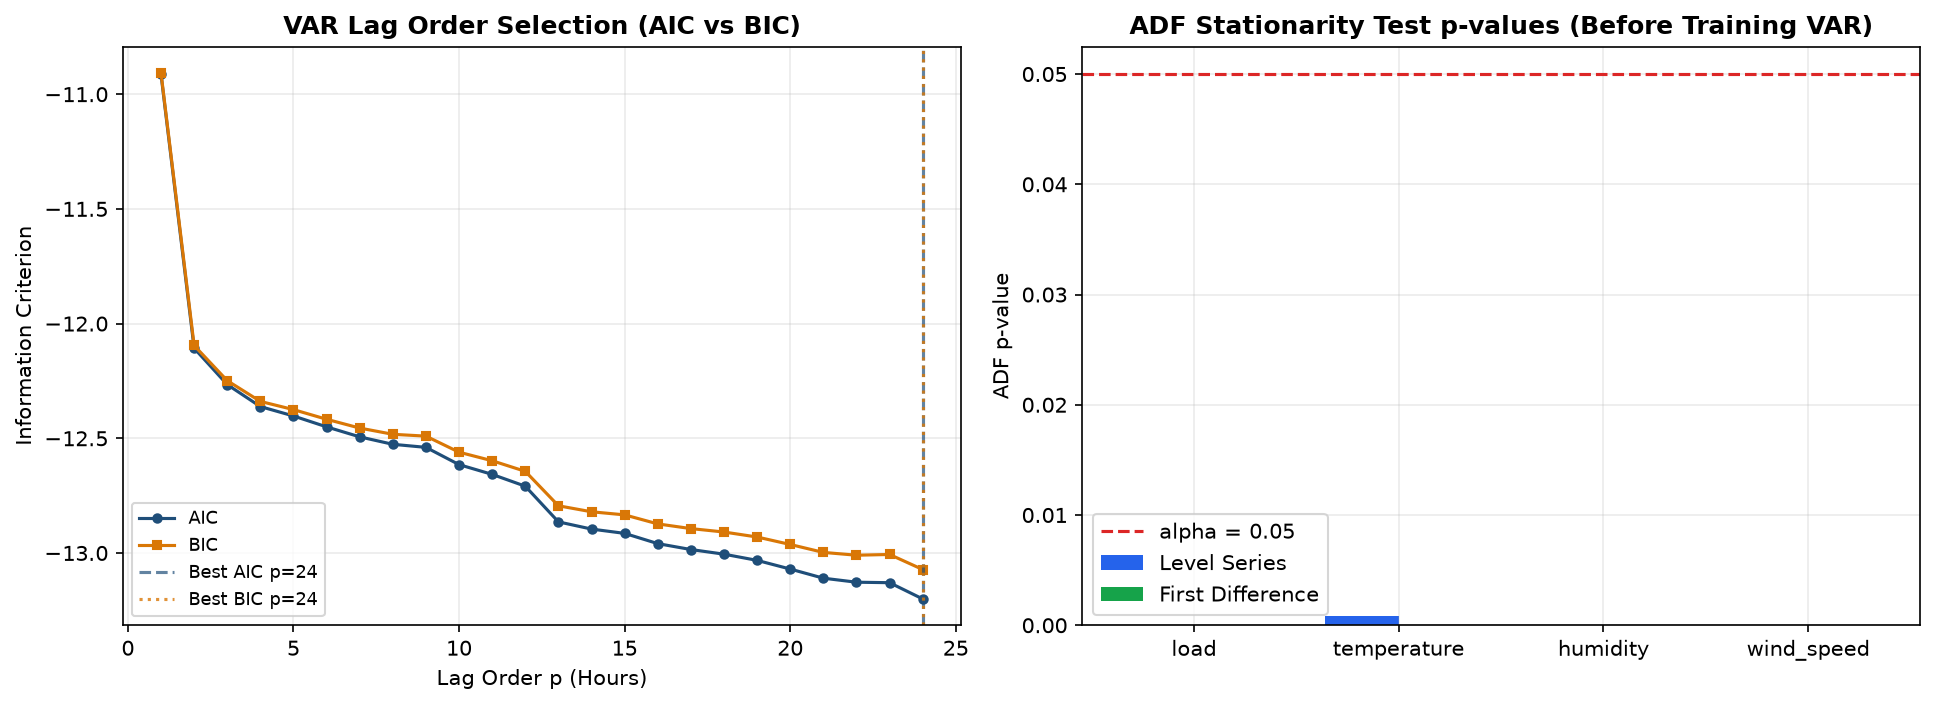

In [11]:
# Biểu đồ 04: Chọn bậc trễ VAR (AIC/BIC) & Kiểm định tính dừng ADF
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].plot(vd["lag_grid"], vd["aic_values"], marker="o", ms=4, color="#1f4e79", label="AIC")
axes[0].plot(vd["lag_grid"], vd["bic_values"], marker="s", ms=4, color="#d97706", label="BIC")
axes[0].axvline(vd["selected_lag_aic"], color="#1f4e79", ls="--", alpha=0.7, label=f"Best AIC p={vd['selected_lag_aic']}")
axes[0].axvline(vd["selected_lag_bic"], color="#d97706", ls=":", alpha=0.8, label=f"Best BIC p={vd['selected_lag_bic']}")
axes[0].set_title("VAR Lag Order Selection (AIC vs BIC)", fontweight="bold")
axes[0].set_xlabel("Lag Order p (Hours)")
axes[0].set_ylabel("Information Criterion")
axes[0].legend(fontsize=8.5)

adf_vars = list(vd["adf_results"].keys())
x_v = np.arange(len(adf_vars))
axes[1].bar(x_v - 0.18, [vd["adf_results"][v]["level_pvalue"] for v in adf_vars], width=0.36, color="#2563eb", label="Level Series")
axes[1].bar(x_v + 0.18, [vd["adf_results"][v]["diff1_pvalue"] for v in adf_vars], width=0.36, color="#16a34a", label="First Difference")
axes[1].axhline(0.05, color="#dc2626", ls="--", lw=1.5, label="alpha = 0.05")
axes[1].set_xticks(x_v)
axes[1].set_xticklabels(adf_vars)
axes[1].set_title("ADF Stationarity Test p-values (Before Training VAR)", fontweight="bold")
axes[1].set_ylabel("ADF p-value")
axes[1].legend()

fig.tight_layout()
fig.savefig(Config.IMAGE_DIR / "04_var_stationarity_and_aic_bic.png", bbox_inches="tight")
plt.show()

---
## Mục 7: Mô Hình 2 — `XGBoost` (Machine Learning)
* Đầu vào: Vector phẳng `99` đặc trưng (96 lags đa biến + 3 rolling/trend). Tinh chỉnh `max_depth` $\in \{4, 6, 8\}$ và `n_estimators` $\in \{500, 800\}$ với `Early Stopping` trên tập Validation.
* Chạy thêm thực nghiệm đối chứng **Ablation (`XGBoost Load-Only 27f`)** để đo lường đóng góp thực tế của biến thời tiết.

In [12]:
xgb_lo = XGBoostMultivariateForecaster.load(Config.MODELS_DIR / Config.MODEL_FILENAMES["XGBoost (Load-Only 27f)"])
xgb_mv, xgb_tuning, _ = tune_xgboost_multivariate(
    prepared.X_xgb_train, prepared.y_train_scaled, prepared.X_xgb_val, prepared.y_val_scaled, prepared.y_val_mw, prepared.scaler
)

xgb_lo_test = xgb_lo.predict_mw(prepared.X_xgb_load_test, prepared.scaler)
xgb_mv_test = xgb_mv.predict_mw(prepared.X_xgb_test, prepared.scaler)

print("XGBoost Tuning Summary:")
print(pd.DataFrame(xgb_tuning)[["name", "best_iteration", "val_rmse_mw", "val_mae_mw"]].to_string(index=False))
print("\nXGBoost (Load-Only 27f)    Test:", evaluate_multivariate_forecast(prepared.y_test_mw, xgb_lo_test))
print("XGBoost (Multivariate 99f) Test:", evaluate_multivariate_forecast(prepared.y_test_mw, xgb_mv_test))
xgb_groups = xgb_mv.get_group_importance_share()
print("Gain Share by Group (%):", xgb_groups)
print("\nTop 10 Features (Gain):")
print(xgb_mv.get_feature_importance().head(10).round(2).to_string())

XGBoost Tuning Summary:
              name  best_iteration  val_rmse_mw  val_mae_mw
Depth=4, Trees=500             500   547.595540  350.359331
Depth=4, Trees=800             800   532.118165  336.925234
Depth=6, Trees=500             488   513.596079  309.942744
Depth=6, Trees=800             800   507.393904  303.819792
Depth=8, Trees=500             491   505.139322  292.053557
Depth=8, Trees=800             797   503.563172  290.652597

XGBoost (Load-Only 27f)    Test: {'RMSE': 429.7949173416298, 'MAE': 274.1849207688478, 'MAPE': 0.9579805575775905, 'R2': 0.9912354243348479}
XGBoost (Multivariate 99f) Test: {'RMSE': 441.4685038036996, 'MAE': 279.88213519659683, 'MAPE': 0.9745493676471432, 'R2': 0.9907528523237221}
Gain Share by Group (%): {'load_lags (24)': 87.83, 'temperature_lags (24)': 2.27, 'humidity_lags (24)': 1.44, 'wind_speed_lags (24)': 1.07, 'rolling_and_trend (3)': 7.39}

Top 10 Features (Gain):
load_lag_1       16.46
load_lag_24       3.37
load_trend_24     2.11
load_la

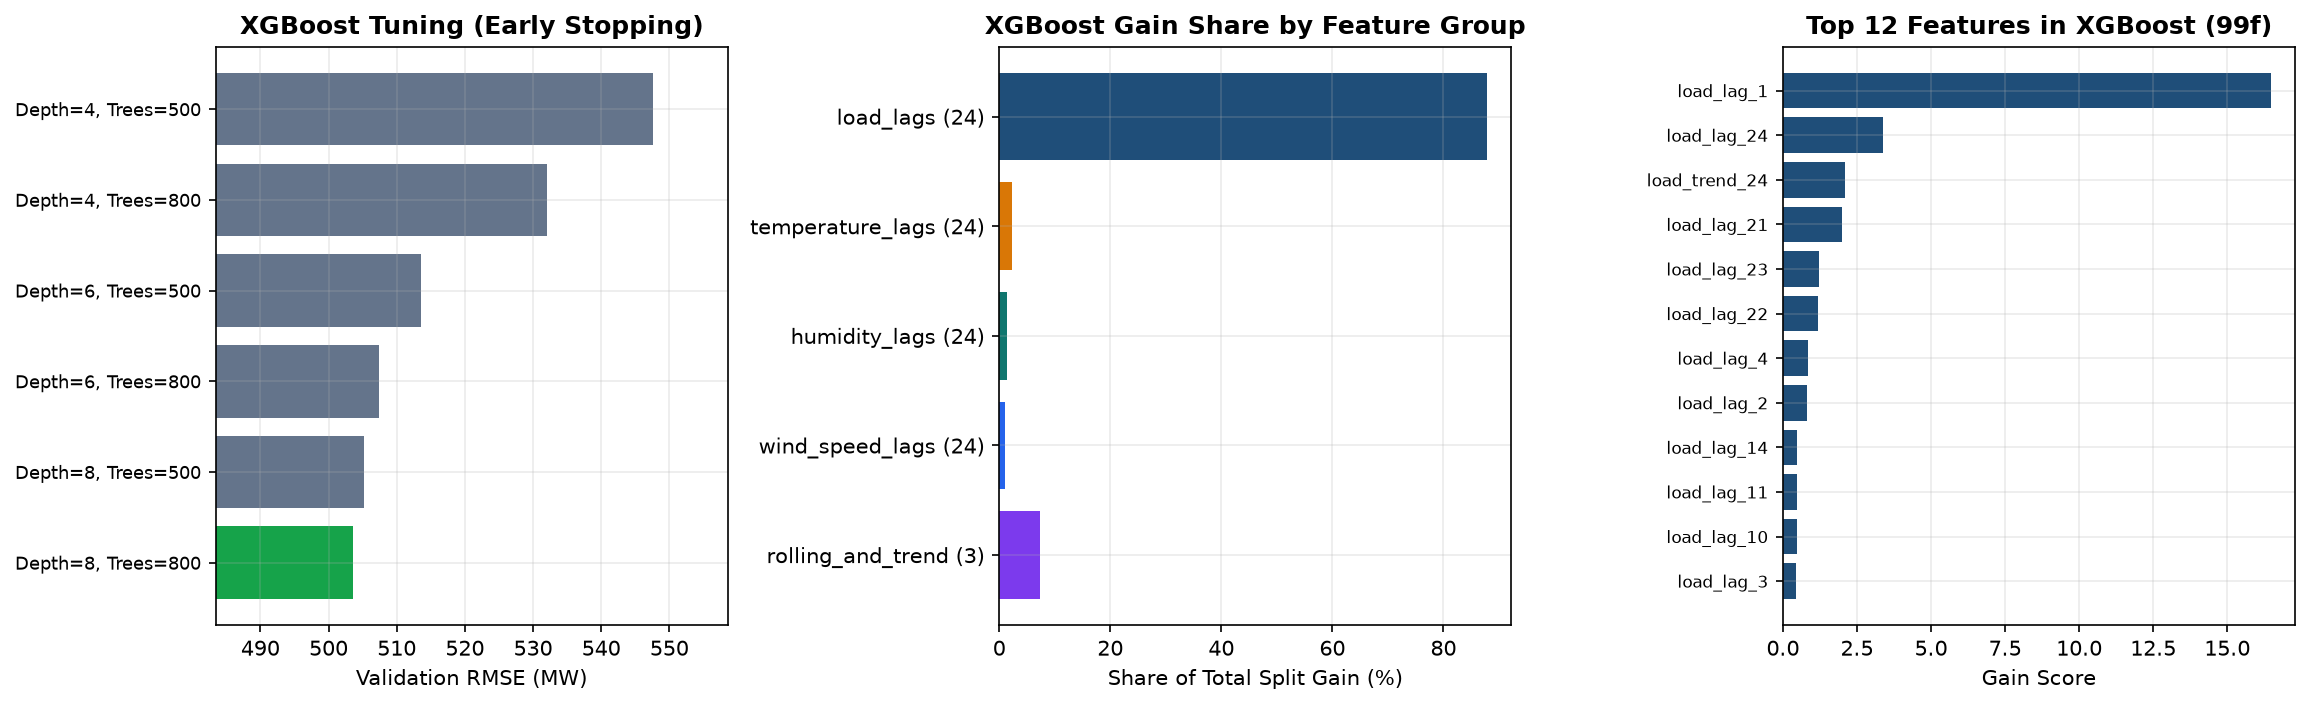

In [13]:
# Biểu đồ 05: XGBoost Tuning, Tỷ trọng Gain theo nhóm biến & Top 12 Features
top_feats = xgb_mv.get_feature_importance()
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.8))

names_t = [r["name"] for r in xgb_tuning]
val_rmses = [r["val_rmse_mw"] for r in xgb_tuning]
best_i = int(np.argmin(val_rmses))
axes[0].barh(np.arange(len(names_t)), val_rmses, color=["#16a34a" if i == best_i else "#64748b" for i in range(len(names_t))])
axes[0].set_yticks(np.arange(len(names_t)))
axes[0].set_yticklabels(names_t, fontsize=8.5)
axes[0].invert_yaxis()
axes[0].set_xlabel("Validation RMSE (MW)")
axes[0].set_title("XGBoost Tuning (Early Stopping)", fontweight="bold")
axes[0].set_xlim(min(val_rmses) * 0.96, max(val_rmses) * 1.02)

axes[1].barh(list(xgb_groups.keys()), list(xgb_groups.values()), color=["#1f4e79", "#d97706", "#0f766e", "#2563eb", "#7c3aed"])
axes[1].invert_yaxis()
axes[1].set_xlabel("Share of Total Split Gain (%)")
axes[1].set_title("XGBoost Gain Share by Feature Group", fontweight="bold")

top12 = top_feats.head(12)
axes[2].barh(top12.index, top12.values, color="#1f4e79")
axes[2].invert_yaxis()
axes[2].set_xlabel("Gain Score")
axes[2].set_title("Top 12 Features in XGBoost (99f)", fontweight="bold")
axes[2].tick_params(axis="y", labelsize=8)

fig.tight_layout()
fig.savefig(Config.IMAGE_DIR / "05_xgboost_tuning_and_feature_importance.png", bbox_inches="tight")
plt.show()

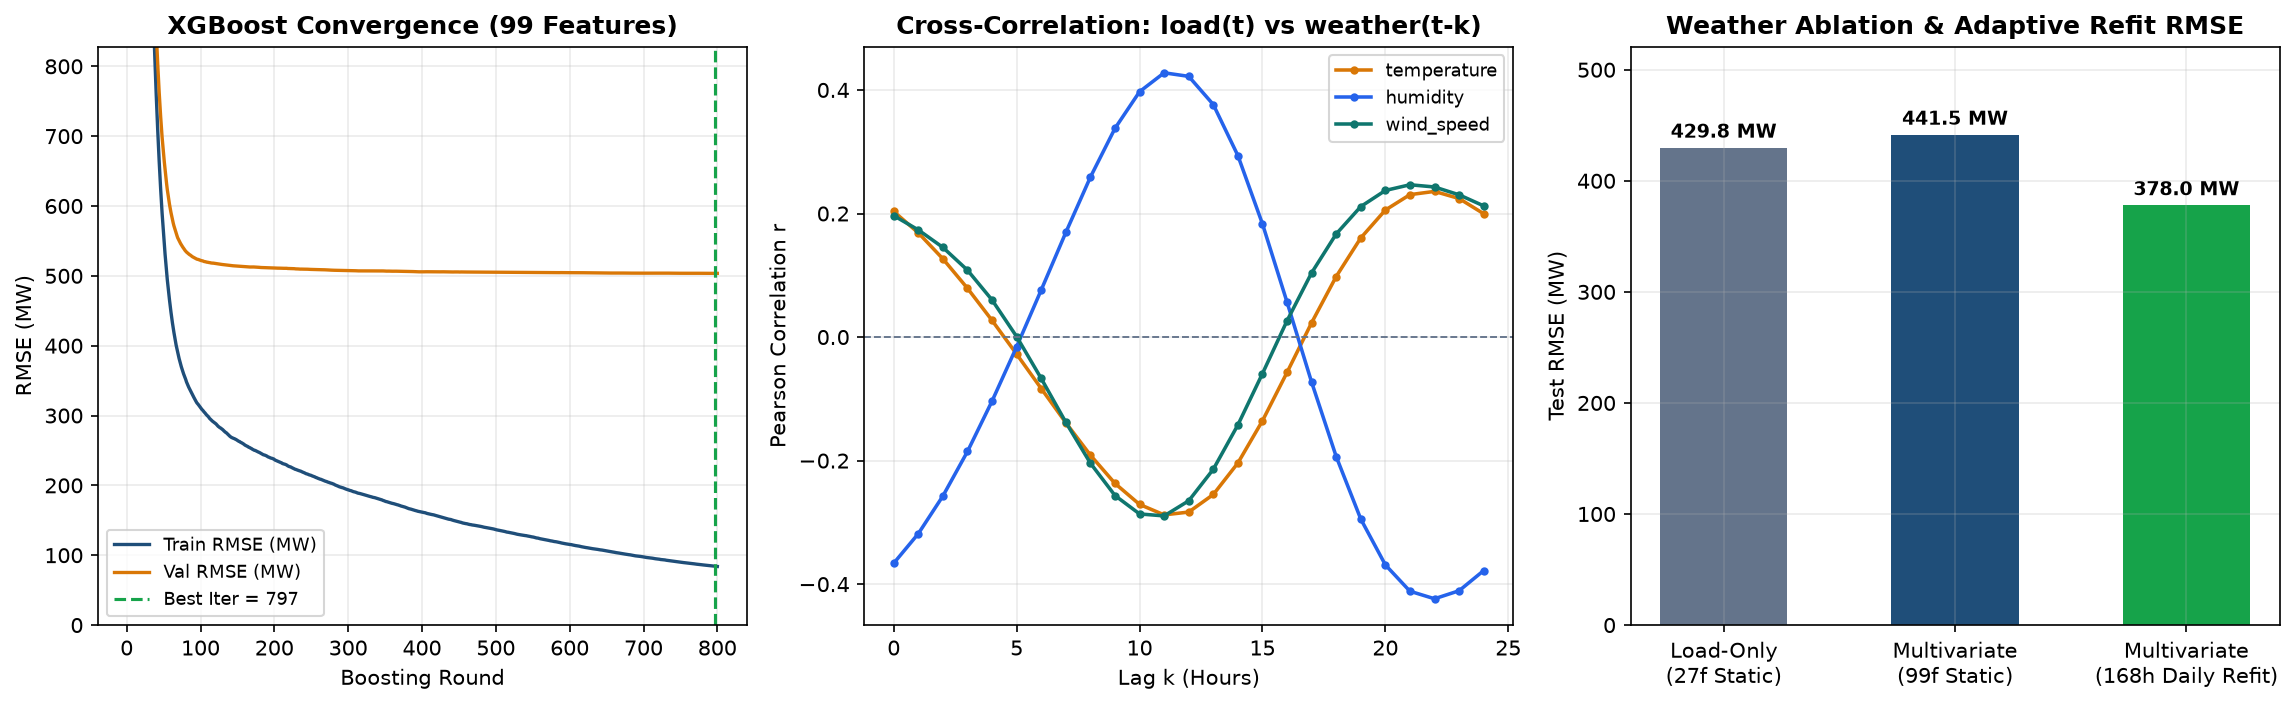

In [14]:
# Biểu đồ 14: Đường cong học tập XGBoost, CCF thời tiết (0..24h) & Weather Ablation
df_lb = pd.read_csv(Config.LEADERBOARD_CSV_PATH)
lb_map = {r["model_name"]: r for r in df_lb.to_dict("records")}
hist = json.loads(Config.EXPERIMENTS_JSON_PATH.read_text(encoding="utf-8"))
wf_summary = hist[-1]["walk_forward_168h"]

fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.8))
ev = xgb_mv.evals_result
std_load = float(prepared.scaler.scale_[0])
tr_xgb_rmse = np.asarray(ev["validation_0"]["rmse"]) * std_load
va_xgb_rmse = np.asarray(ev["validation_1"]["rmse"]) * std_load
axes[0].plot(np.arange(1, len(tr_xgb_rmse) + 1), tr_xgb_rmse, color="#1f4e79", lw=1.6, label="Train RMSE (MW)")
axes[0].plot(np.arange(1, len(va_xgb_rmse) + 1), va_xgb_rmse, color="#d97706", lw=1.6, label="Val RMSE (MW)")
if xgb_mv.best_iteration is not None:
    axes[0].axvline(xgb_mv.best_iteration + 1, color="#16a34a", ls="--", label=f"Best Iter = {xgb_mv.best_iteration + 1}")
axes[0].set_title("XGBoost Convergence (99 Features)", fontweight="bold")
axes[0].set_xlabel("Boosting Round")
axes[0].set_ylabel("RMSE (MW)")
axes[0].set_ylim(0, max(va_xgb_rmse[50], tr_xgb_rmse[50]) * 1.25)
axes[0].legend(fontsize=8.5)

lags_c = np.arange(0, 25)
for col, color in [("temperature", "#d97706"), ("humidity", "#2563eb"), ("wind_speed", "#0f766e")]:
    axes[1].plot(lags_c, [df_clean["load"].corr(df_clean[col].shift(k)) for k in lags_c], marker="o", ms=3, lw=1.7, color=color, label=col)
axes[1].axhline(0, color="#64748b", ls="--", lw=0.9)
axes[1].set_title("Cross-Correlation: load(t) vs weather(t-k)", fontweight="bold")
axes[1].set_xlabel("Lag k (Hours)")
axes[1].set_ylabel("Pearson Correlation r")
axes[1].legend(fontsize=8.5)

ab_labels = ["Load-Only\n(27f Static)", "Multivariate\n(99f Static)", "Multivariate\n(168h Daily Refit)"]
ab_vals = [lb_map["XGBoost (Load-Only 27f)"]["test_rmse"], lb_map["XGBoost (Multivariate 99f)"]["test_rmse"], wf_summary["XGBoost (Multivariate 99f)"]["periodic_refit_rmse"]]
bars = axes[2].bar(ab_labels, ab_vals, color=["#64748b", "#1f4e79", "#16a34a"], width=0.55)
for b, v in zip(bars, ab_vals):
    axes[2].text(b.get_x() + b.get_width() / 2, v + 5, f"{v:.1f} MW", ha="center", va="bottom", fontsize=9, fontweight="bold")
axes[2].set_ylim(0, max(ab_vals) * 1.18)
axes[2].set_title("Weather Ablation & Adaptive Refit RMSE", fontweight="bold")
axes[2].set_ylabel("Test RMSE (MW)")

fig.tight_layout()
fig.savefig(Config.IMAGE_DIR / "14_xgboost_learning_curves_and_weather_ablation.png", bbox_inches="tight")
plt.show()

---
## Mục 8: Mô Hình 3 — `LSTM` (Deep Learning)
* Đầu vào: Tensor 3D `(batch_samples, 24, 4)`.
* Kiến trúc mạng: `LSTM(64, return_sequences=True) -> LSTM(32) -> Dense(1)` | Loss: `MSE` | Optimizer: `Adam`.

In [15]:
lstm_model = LSTMForecaster(Config.LSTM_PARAMS).fit(
    prepared.X_lstm_train, prepared.y_train_scaled, prepared.X_lstm_val, prepared.y_val_scaled
)
lstm_model.model.summary()
lstm_test_mw = lstm_model.predict_mw(prepared.X_lstm_test, prepared.scaler)
print("\nLSTM Test Metrics:", evaluate_multivariate_forecast(prepared.y_test_mw, lstm_test_mw))

Model: "sequential"
┌─────────────────────────────────┬────────────────────────┬───────────────┐
│ Layer (type)                    │ Output Shape           │       Param # │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 24, 64)         │        17,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘
 Total params: 90,341 (352.90 KB)
 Trainable params: 30,113 (117.63 KB)
 Non-trainable params: 0 (0.00 B)
 Optimizer params: 60,228 (235.27 KB)

LSTM Test Metrics: {'RMSE': 1163.3689705308461, 'MAE': 882.6696862916547, 'MAPE': 3.093462507492524, 'R2': 0.9357839931638701}


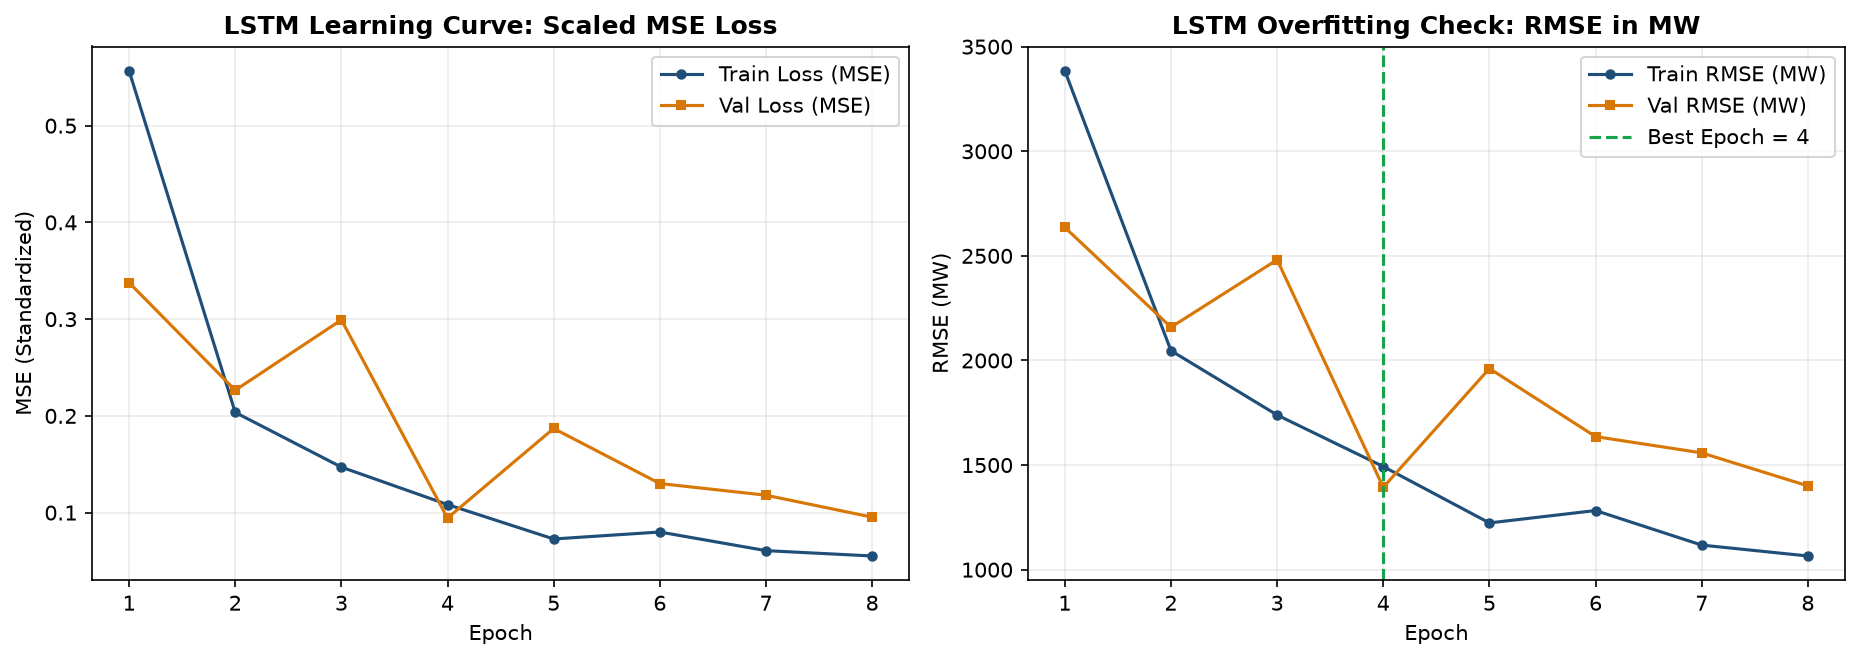

In [16]:
# Biểu đồ 06: Đường cong học tập LSTM (MSE & MW RMSE qua các epochs)
lstm_hist = lstm_model.history_
epochs_l = np.arange(1, len(lstm_hist["loss"]) + 1)
tr_l_rmse = np.sqrt(np.asarray(lstm_hist["loss"])) * float(prepared.scaler.scale_[0])
va_l_rmse = np.sqrt(np.asarray(lstm_hist["val_loss"])) * float(prepared.scaler.scale_[0])

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.5))
axes[0].plot(epochs_l, lstm_hist["loss"], marker="o", ms=4, color="#1f4e79", label="Train Loss (MSE)")
axes[0].plot(epochs_l, lstm_hist["val_loss"], marker="s", ms=4, color="#d97706", label="Val Loss (MSE)")
axes[0].set_title("LSTM Learning Curve: Scaled MSE Loss", fontweight="bold")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("MSE (Standardized)")
axes[0].legend()

axes[1].plot(epochs_l, tr_l_rmse, marker="o", ms=4, color="#1f4e79", label="Train RMSE (MW)")
axes[1].plot(epochs_l, va_l_rmse, marker="s", ms=4, color="#d97706", label="Val RMSE (MW)")
best_ep = int(np.argmin(va_l_rmse)) + 1
axes[1].axvline(best_ep, color="#16a34a", ls="--", label=f"Best Epoch = {best_ep}")
axes[1].set_title("LSTM Overfitting Check: RMSE in MW", fontweight="bold")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("RMSE (MW)")
axes[1].legend()

fig.tight_layout()
fig.savefig(Config.IMAGE_DIR / "06_lstm_learning_curves.png", bbox_inches="tight")
plt.show()

---
## Mục 9 & 10: Walk-Forward Validation (Backtesting) & Bảng Xếp Hạng Tổng Hợp
* Áp dụng quy trình **Walk-forward Validation** mô phỏng vận hành thực tế (`Train -> predict t+1 -> cập nhật chuỗi -> predict t+2 -> ...`).
* Đánh giá toàn diện trên 3 độ đo: **RMSE**, **MAE**, **MAPE**.

In [17]:
print("=== FINAL MODEL LEADERBOARD ON TEST SET (5,260 HOURS) ===")
print(df_lb[["rank", "model_name", "feature_set", "train_rmse", "val_rmse", "test_rmse", "test_mae", "test_mape", "test_r2"]].to_string(index=False))

print("\n=== 168h Walk-Forward Backtest (Static vs Daily Refit) ===")
print(pd.DataFrame(wf_summary).T.round(2).to_string())

=== FINAL MODEL LEADERBOARD ON TEST SET (5,260 HOURS) ===
 rank                  model_name            feature_set  train_rmse  val_rmse  test_rmse  test_mae  test_mape  test_r2
    1     XGBoost (Load-Only 27f)  24 Load Lags + 3 Roll    233.2889  484.8204   429.7949  274.1849     0.9580 0.991235
    2  XGBoost (Multivariate 99f) 96 Lags + 3 Roll/Trend     84.1982  503.5632   441.4685  279.8821     0.9745 0.990753
    3                         VAR          4 Vars x p=24    765.8750  793.6779   686.2723  482.7235     1.7054 0.977654
    4            LSTM (64->32->1)       3D Tensor (24x4)   1257.0394 1393.6287  1163.3690  882.6697     3.0935 0.935784
    5   Persistence Naive (lag_1)     1 Lag (load_lag_1)   1421.5062 1506.8220  1383.3733 1045.6605     3.6871 0.909200
    6 Seasonal Naive 24h (lag_24)    1 Lag (load_lag_24)   3513.9596 3506.8726  3623.0374 2533.8329     8.7661 0.377192

=== 168h Walk-Forward Backtest (Static vs Daily Refit) ===
                            static_rmse  p

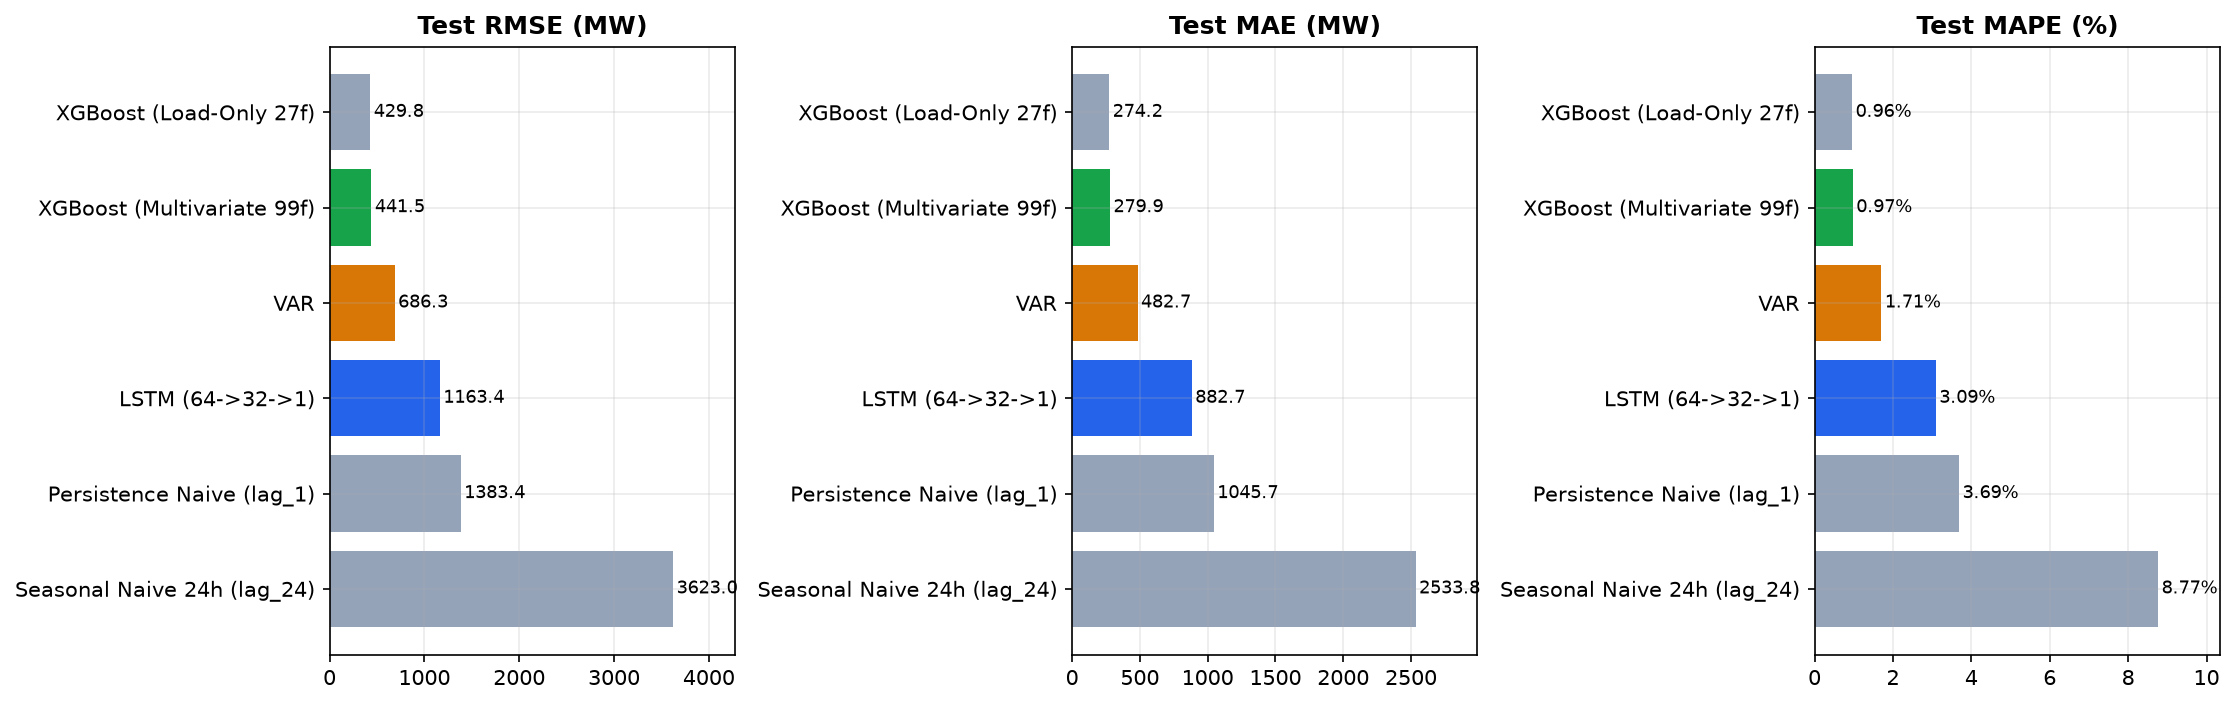

In [18]:
# Biểu đồ 07: Đối chiếu trực tiếp Test RMSE, MAE và MAPE của 6 mô hình
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
bar_cols = ["#16a34a" if "Multivariate" in n else ("#2563eb" if "LSTM" in n else ("#d97706" if "VAR" in n else "#94a3b8")) for n in df_lb["model_name"]]
for ax, (col, title) in zip(axes, [("test_rmse", "Test RMSE (MW)"), ("test_mae", "Test MAE (MW)"), ("test_mape", "Test MAPE (%)")]):
    bars = ax.barh(df_lb["model_name"], df_lb[col], color=bar_cols)
    ax.invert_yaxis()
    ax.set_title(title, fontweight="bold")
    for b, val in zip(bars, df_lb[col]):
        ax.text(val + df_lb[col].max() * 0.01, b.get_y() + b.get_height() / 2, f"{val:.2f}%" if col == "test_mape" else f"{val:.1f}", va="center", fontsize=8.5)
    ax.set_xlim(0, df_lb[col].max() * 1.18)

fig.tight_layout()
fig.savefig(Config.IMAGE_DIR / "07_models_comparison_metrics.png", bbox_inches="tight")
plt.show()

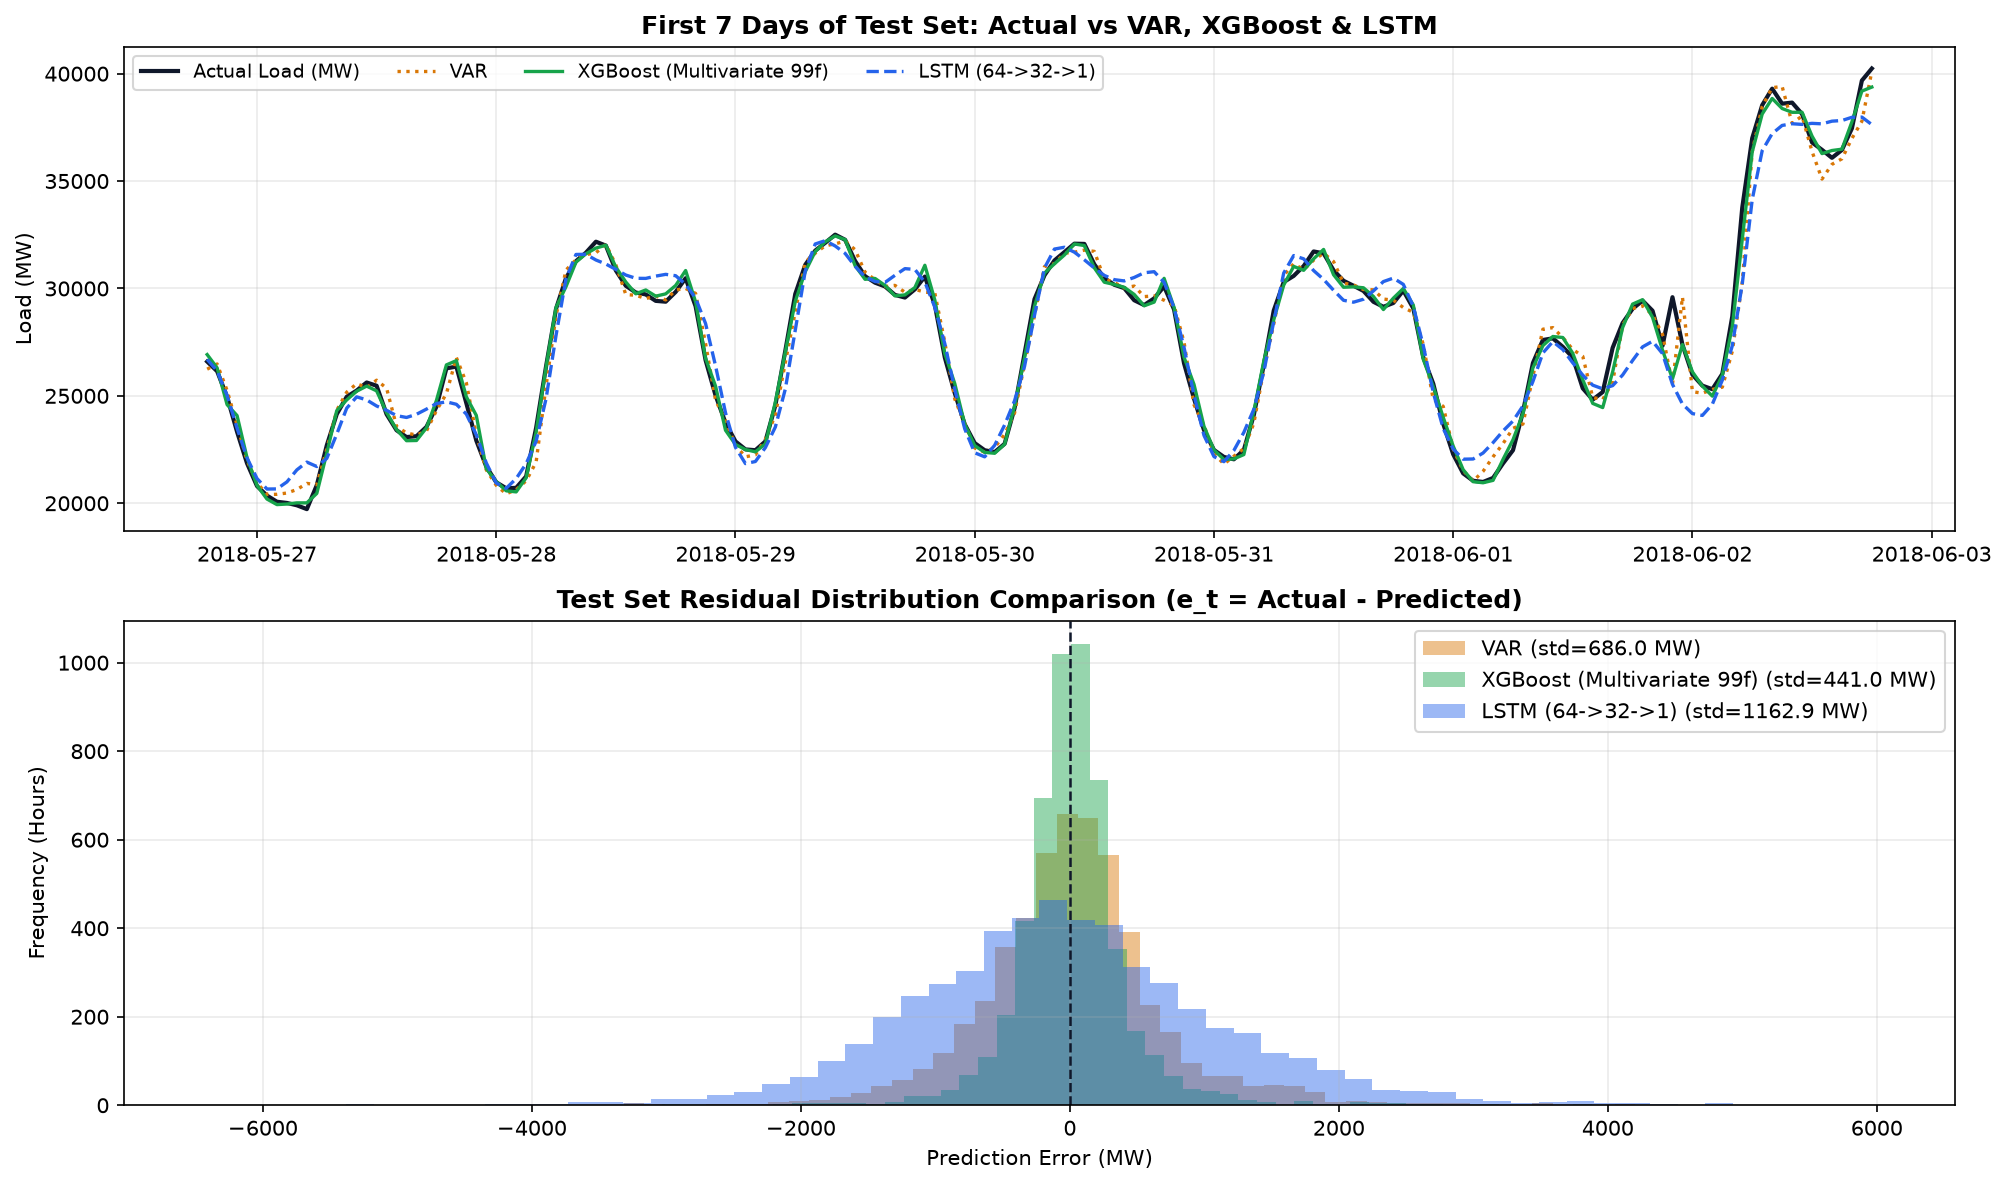

In [19]:
# Biểu đồ 08: Dự báo vs Thực tế trên 7 ngày đầu tập Test & Phân phối phần dư
preds_test_map = {"VAR": var_test_mw, "XGBoost (Multivariate 99f)": xgb_mv_test, "LSTM (64->32->1)": lstm_test_mw}
win_n = min(168, len(prepared.idx_test))
ts_w = prepared.idx_test[:win_n]

fig, axes = plt.subplots(2, 1, figsize=(13.5, 8))
axes[0].plot(ts_w, prepared.y_test_mw[:win_n], color="#0f172a", lw=2.0, label="Actual Load (MW)")
pal_m = {"VAR": "#d97706", "XGBoost (Multivariate 99f)": "#16a34a", "LSTM (64->32->1)": "#2563eb"}
sty_m = {"VAR": ":", "XGBoost (Multivariate 99f)": "-", "LSTM (64->32->1)": "--"}
for name, col in pal_m.items():
    axes[0].plot(ts_w, preds_test_map[name][:win_n], color=col, ls=sty_m[name], lw=1.6, label=name)
axes[0].set_title("First 7 Days of Test Set: Actual vs VAR, XGBoost & LSTM", fontweight="bold")
axes[0].set_ylabel("Load (MW)")
axes[0].legend(ncol=4, fontsize=9)

for name, col in pal_m.items():
    err = prepared.y_test_mw - preds_test_map[name]
    axes[1].hist(err, bins=60, alpha=0.45, color=col, label=f"{name} (std={np.std(err):.1f} MW)")
axes[1].axvline(0, color="#0f172a", lw=1.2, ls="--")
axes[1].set_title("Test Set Residual Distribution Comparison (e_t = Actual - Predicted)", fontweight="bold")
axes[1].set_xlabel("Prediction Error (MW)")
axes[1].set_ylabel("Frequency (Hours)")
axes[1].legend()

fig.tight_layout()
fig.savefig(Config.IMAGE_DIR / "08_predictions_vs_actual_test.png", bbox_inches="tight")
plt.show()

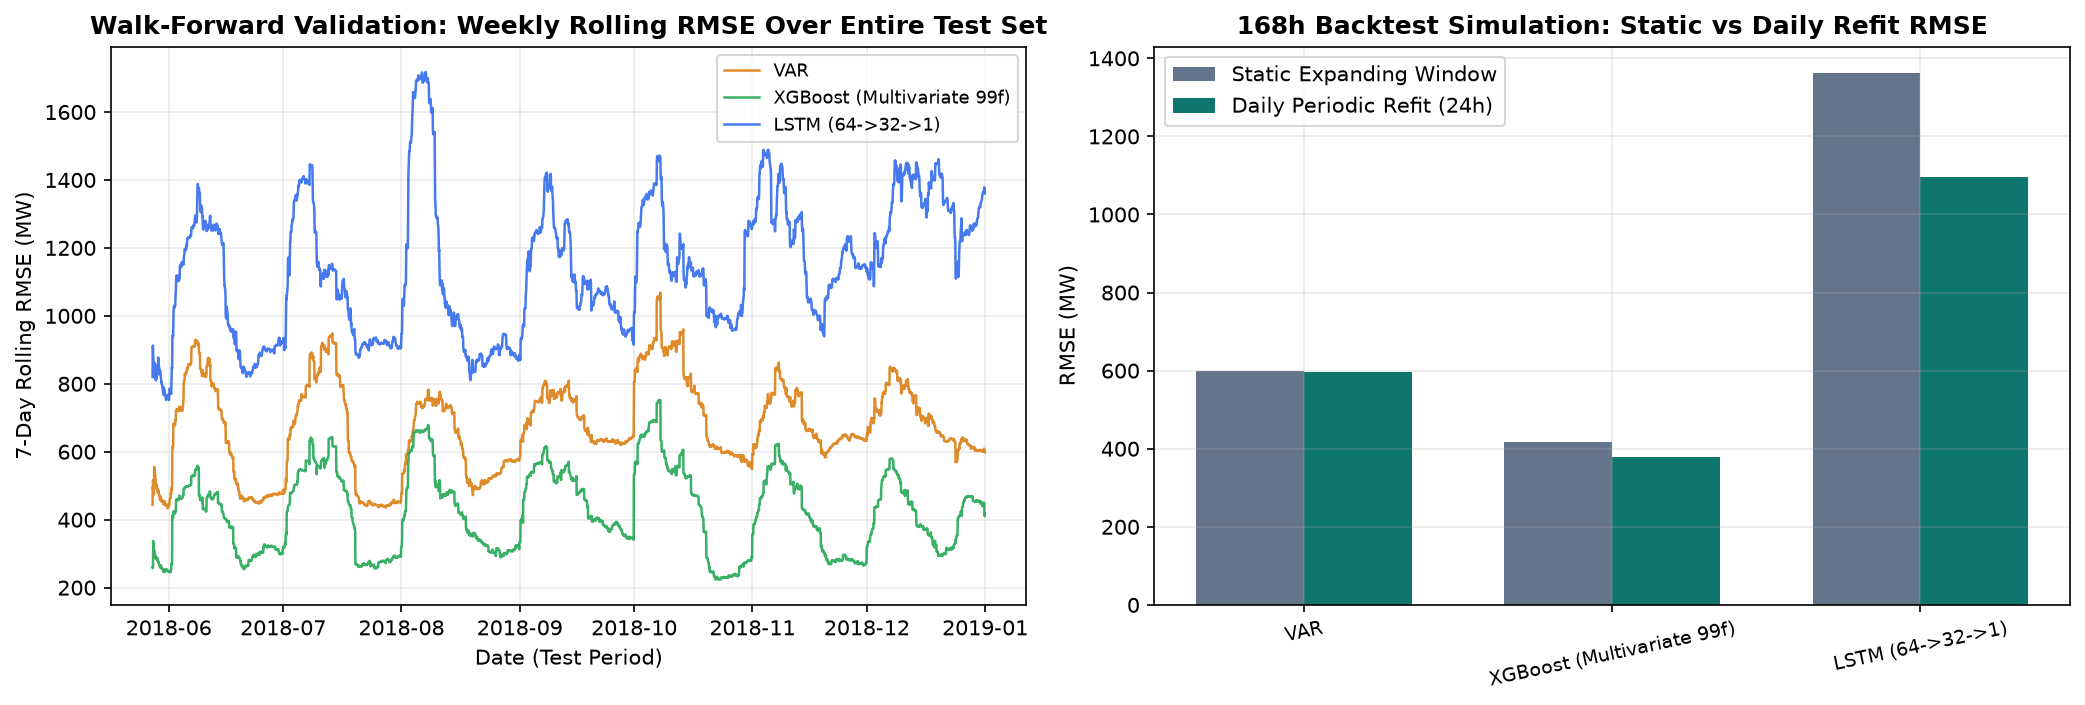

In [20]:
# Biểu đồ 09: Walk-Forward Validation Backtest (Rolling 168h RMSE & Daily Refit)
daily_rmse_df = pd.DataFrame({
    m: np.sqrt(pd.Series((prepared.y_test_mw - preds_test_map[m]) ** 2, index=prepared.idx_test).rolling(168, min_periods=24).mean()).values
    for m in preds_test_map
}, index=prepared.idx_test)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for m, col in pal_m.items():
    axes[0].plot(daily_rmse_df.index, daily_rmse_df[m], lw=1.2, alpha=0.85, color=col, label=m)
axes[0].set_title("Walk-Forward Validation: Weekly Rolling RMSE Over Entire Test Set", fontweight="bold")
axes[0].set_xlabel("Date (Test Period)")
axes[0].set_ylabel("7-Day Rolling RMSE (MW)")
axes[0].legend(fontsize=8.5)

m_keys = list(wf_summary.keys())
x_wf = np.arange(len(m_keys))
axes[1].bar(x_wf - 0.175, [wf_summary[m]["static_rmse"] for m in m_keys], width=0.35, color="#64748b", label="Static Expanding Window")
axes[1].bar(x_wf + 0.175, [wf_summary[m]["periodic_refit_rmse"] for m in m_keys], width=0.35, color="#0f766e", label="Daily Periodic Refit (24h)")
axes[1].set_xticks(x_wf)
axes[1].set_xticklabels(m_keys, rotation=12, fontsize=9)
axes[1].set_title("168h Backtest Simulation: Static vs Daily Refit RMSE", fontweight="bold")
axes[1].set_ylabel("RMSE (MW)")
axes[1].legend()

fig.tight_layout()
fig.savefig(Config.IMAGE_DIR / "09_walk_forward_backtest.png", bbox_inches="tight")
plt.show()

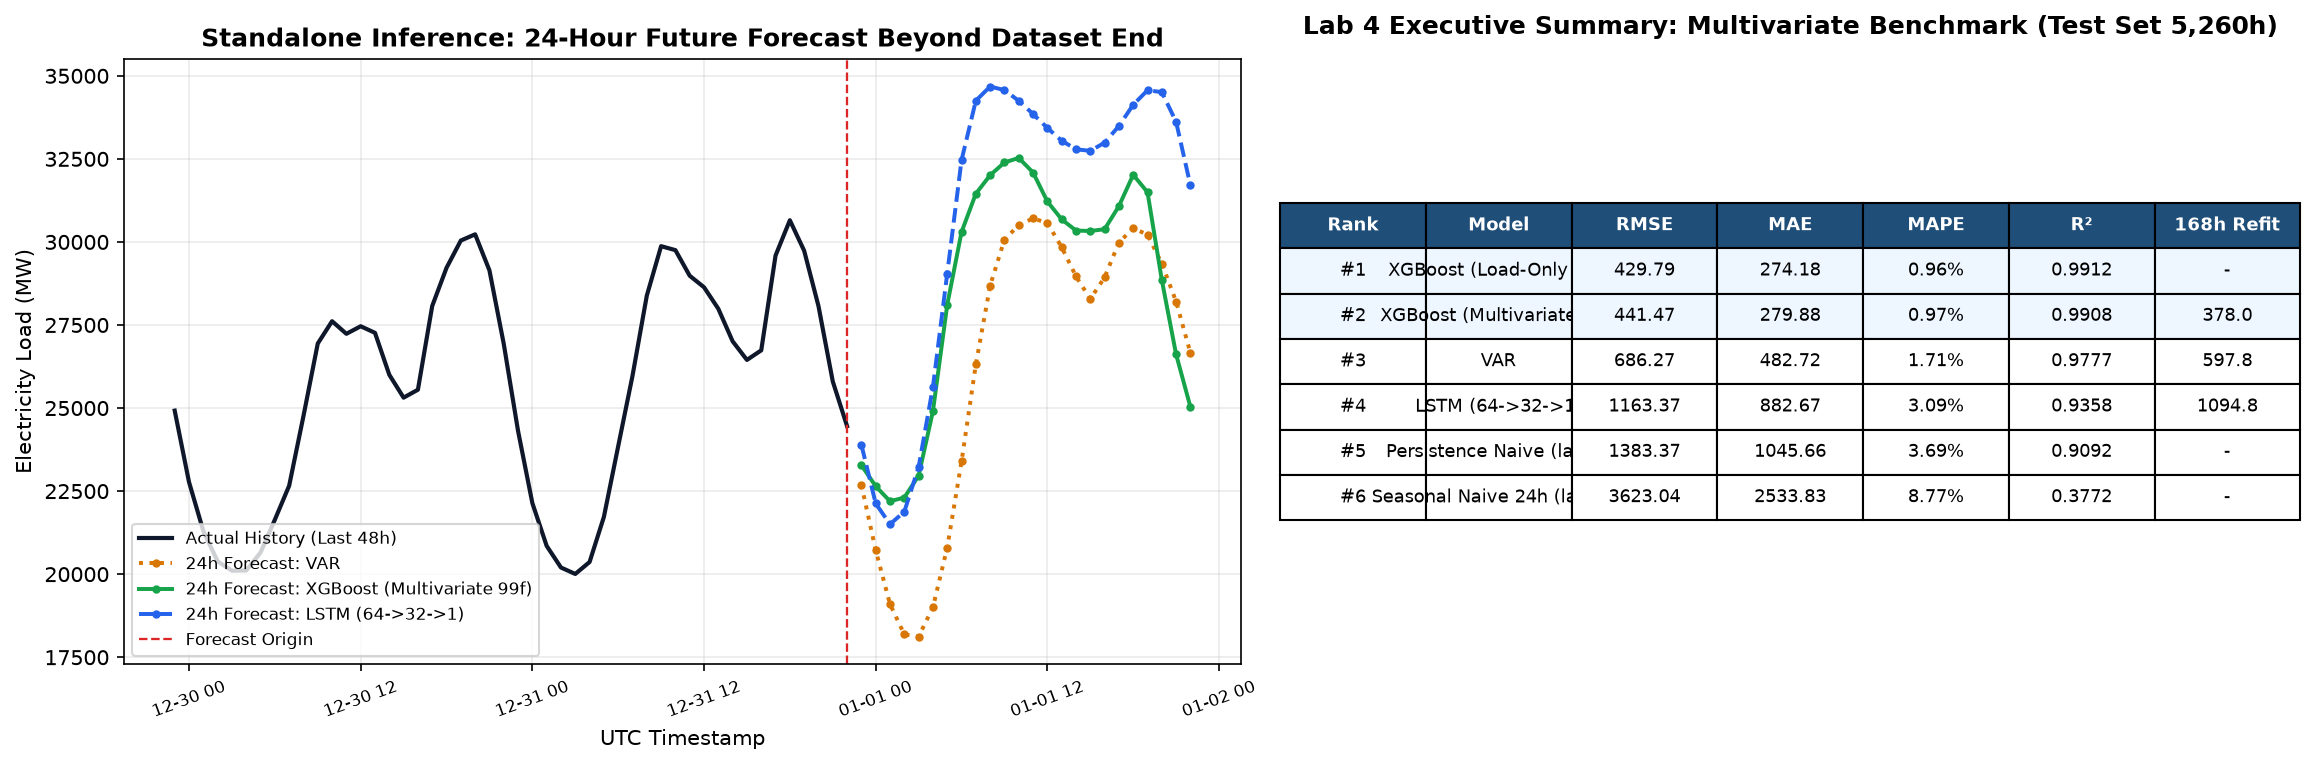

In [21]:
# Biểu đồ 15: Dự báo 24h tương lai ngoài chuỗi & Bảng tổng kết Lab 4
df_pred = pd.read_csv(Config.PREDICTIONS_CSV_PATH)
fut = df_pred[df_pred["record_type"] == "future_forecast"].copy()
fut["dt"] = pd.to_datetime(fut["Datetime"])
hist_tail = df_clean["load"].iloc[-48:]

fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.2), gridspec_kw={"width_ratios": [1.15, 1.0]})
axes[0].plot(hist_tail.index, hist_tail.values, color="#0f172a", lw=2.0, label="Actual History (Last 48h)")
for m_name, col in pal_m.items():
    sub_f = fut[fut["model_name"] == m_name].sort_values("horizon_step")
    axes[0].plot(sub_f["dt"], sub_f["predicted_load_MW"], color=col, ls=sty_m[m_name], lw=1.9, marker="o", ms=3, label=f"24h Forecast: {m_name}")
axes[0].axvline(hist_tail.index.max(), color="#dc2626", ls="--", lw=1.1, label="Forecast Origin")
axes[0].set_title("Standalone Inference: 24-Hour Future Forecast Beyond Dataset End", fontweight="bold")
axes[0].set_xlabel("UTC Timestamp")
axes[0].set_ylabel("Electricity Load (MW)")
axes[0].tick_params(axis="x", rotation=20, labelsize=8)
axes[0].legend(fontsize=8, loc="lower left")

axes[1].axis("off")
axes[1].set_title("Lab 4 Executive Summary: Multivariate Benchmark (Test Set 5,260h)", fontweight="bold", pad=12)
cell_rows = [[f"#{r['rank']}", r["model_name"], f"{r['test_rmse']:.2f}", f"{r['test_mae']:.2f}", f"{r['test_mape']:.2f}%", f"{r['test_r2']:.4f}", f"{wf_summary[r['model_name']]['periodic_refit_rmse']:.1f}" if r["model_name"] in wf_summary else "-"] for r in df_lb.to_dict("records")]
tbl = axes[1].table(cellText=cell_rows, colLabels=["Rank", "Model", "RMSE", "MAE", "MAPE", "R²", "168h Refit"], loc="center", cellLoc="center")
tbl.auto_set_font_size(False)
tbl.set_fontsize(8.5)
tbl.scale(1.05, 1.8)
for (ri, ci), cell in tbl.get_celld().items():
    if ri == 0:
        cell.set_facecolor("#1f4e79")
        cell.set_text_props(color="white", fontweight="bold")
    elif ri <= 2:
        cell.set_facecolor("#eef6ff")

fig.tight_layout()
fig.savefig(Config.IMAGE_DIR / "15_future_24h_forecast_and_lab4_summary.png", bbox_inches="tight")
plt.show()

---
## Mục 11: Phân Tích Chẩn Đoán & Trả Lời 6 Câu Hỏi
1. **Biến thời tiết nào ảnh hưởng mạnh nhất đến điện năng?** (`temperature` có Granger causality mạnh nhất $p = 6.79 \times 10^{-69}$ và chiếm Gain cao nhất trong nhóm thời tiết; `humidity` có tương quan tuyến tính $|r|=0.366$ mạnh nhất do nghịch pha nhiệt độ ngày–đêm).
2. **Khi nào VAR thất bại?** Khi quan hệ mang tính phi tuyến (chữ U theo nhiệt độ: điều hòa mùa hè & sưởi mùa đông) và khi độ trễ cao làm số tham số phình to (`388` tham số).
3. **XGBoost học được thông tin gì từ thời tiết?** Bắt được các ngưỡng phi tuyến giữa nhiệt độ và phụ tải; đạt RMSE thấp nhất ở trời nóng (`> 25°C`: `405.26 MW`).
4. **LSTM học được chu kỳ nào (ngày, tuần)?** Với cửa sổ `L = 24`, LSTM nắm được **chu kỳ ngày (24h)** nhưng không nhìn trực tiếp **chu kỳ tuần (168h)** từ một mẫu đơn lẻ.
5. **LSTM có bị overfitting không?** `Train RMSE = 1,257 MW`, `Val RMSE = 1,394 MW`, `Test RMSE = 1,163 MW` (Gap `-93.7 MW`) $\rightarrow$ **không bị overfitting**, ngược lại hơi **underfitting** do dừng sớm ở epoch `8`.
6. **Sự khác biệt giữa Machine Learning (`XGBoost`) và Deep Learning (`LSTM`)?** Xem phân tích chi tiết theo giờ và chế độ nhiệt độ bên dưới.

=== Test RMSE (MW) by Temperature Regime ===
                   VAR  XGBoost (Multivariate 99f)  LSTM (64->32->1)
temp_bin                                                            
Cold (<10°C)    734.69                      441.50           1393.65
Mild (10-18°C)  694.20                      416.73           1156.04
Warm (18-25°C)  720.02                      481.66           1057.11
Hot (>25°C)     588.88                      405.26           1189.32


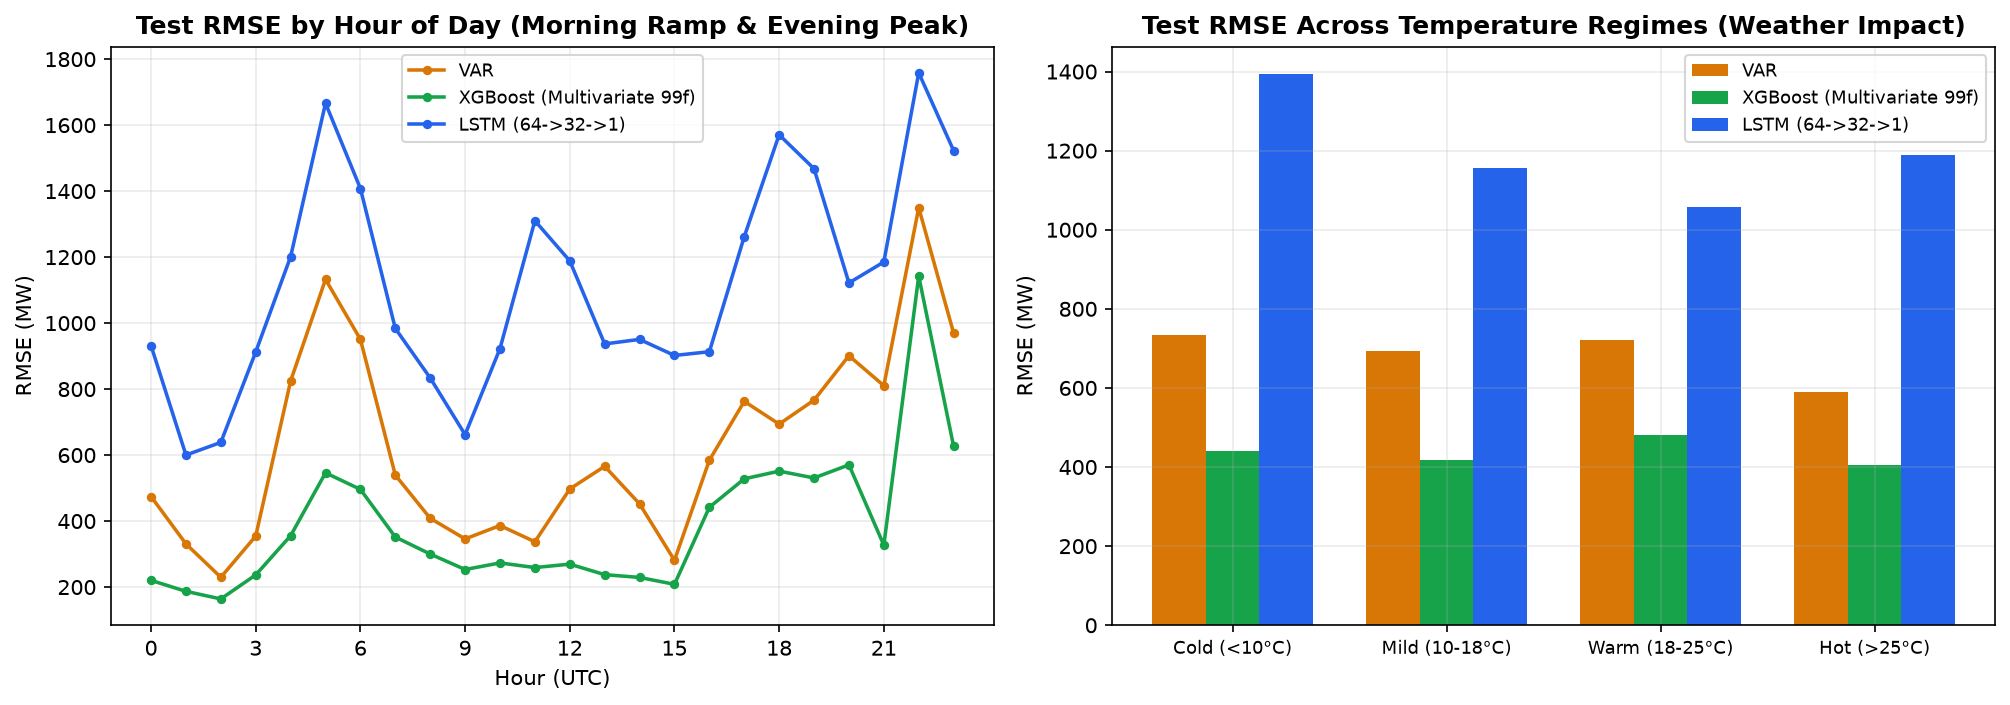

In [22]:
# Biểu đồ 10: Phân tích sai số theo giờ trong ngày & theo chế độ nhiệt độ (Q1-Q6)
df_diag = pd.DataFrame({
    "actual": prepared.y_test_mw,
    "hour": prepared.idx_test.hour,
    "temp": prepared.df_test_raw["temperature"].values,
    "VAR": var_test_mw,
    "XGBoost (Multivariate 99f)": xgb_mv_test,
    "LSTM (64->32->1)": lstm_test_mw,
})
df_diag["temp_bin"] = pd.cut(df_diag["temp"], bins=[-5, 10, 18, 25, 45], labels=["Cold (<10°C)", "Mild (10-18°C)", "Warm (18-25°C)", "Hot (>25°C)"])

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))
temp_tbl = {}
for m, col in pal_m.items():
    sq = (df_diag["actual"] - df_diag[m]) ** 2
    df_diag[f"sq_{m}"] = sq
    hr_r = np.sqrt(df_diag.groupby("hour")[f"sq_{m}"].mean())
    axes[0].plot(hr_r.index, hr_r.values, marker="o", ms=3.5, lw=1.7, color=col, label=m)
    temp_tbl[m] = np.sqrt(df_diag.groupby("temp_bin", observed=False)[f"sq_{m}"].mean()).round(2)

print("=== Test RMSE (MW) by Temperature Regime ===")
print(pd.DataFrame(temp_tbl).to_string())

axes[0].set_title("Test RMSE by Hour of Day (Morning Ramp & Evening Peak)", fontweight="bold")
axes[0].set_xlabel("Hour (UTC)")
axes[0].set_ylabel("RMSE (MW)")
axes[0].set_xticks(range(0, 24, 3))
axes[0].legend(fontsize=8.5)

x_tb = np.arange(4)
for idx_m, (m, col) in enumerate(pal_m.items()):
    axes[1].bar(x_tb + (idx_m - 1) * 0.25, temp_tbl[m].values, width=0.25, color=col, label=m)
axes[1].set_xticks(x_tb)
axes[1].set_xticklabels(["Cold (<10°C)", "Mild (10-18°C)", "Warm (18-25°C)", "Hot (>25°C)"], fontsize=8.5)
axes[1].set_title("Test RMSE Across Temperature Regimes (Weather Impact)", fontweight="bold")
axes[1].set_ylabel("RMSE (MW)")
axes[1].legend(fontsize=8.5)

fig.tight_layout()
fig.savefig(Config.IMAGE_DIR / "10_residual_and_hourly_error_analysis.png", bbox_inches="tight")
plt.show()

---
## Mục 12: Bài Tập Nâng Cao — Traffic Forecasting (`METR-LA` / `PEMS-BAY`)
* **Đặc trưng bài toán không gian–thời gian (Spatio-Temporal):** $207$ trạm cảm biến đo tốc độ giao thông mỗi `5 phút`, vector trạng thái tại mỗi thời điểm có $207$ chiều: $X_t = [speed_1, speed_2, \dots, speed_{207}] \in \mathbb{R}^{207}$.
* **Công thức dự báo đa bước (Multi-step Horizons $15, 30, 60$ phút):**
  $$[X_{t-12}, \dots, X_t] \Rightarrow X_{t+3},\ X_{t+6},\ X_{t+12}$$
* **Hạn chế của VAR/XGBoost/LSTM thuần trên `METR-LA`:**
  1. `VAR` bùng nổ chiều ma trận ($207^2 \times p$ tham số $\rightarrow$ bất khả thi).
  2. `XGBoost` phải train $207 \times 3 = 621$ mô hình tách biệt, bỏ qua cấu trúc đồ thị mạng lưới đường cao tốc.
  3. **Giải pháp chuẩn DCRNN (*Diffusion Convolutional Recurrent Neural Network*):** Mô hình hóa mạng đường bộ như đồ thị có hướng $G = (V, E, W)$ (với $|V|=207$), thay phép nhân ma trận trong GRU bằng **Diffusion Convolution** hai chiều để lan truyền dòng giao thông xuôi–ngược dòng trên đồ thị.